# ЛАБОРАТОРНА РОБОТА № 4

## Візуальний аналіз даних та часові ряди — аналіз у двох середовищах

**Курс:** СК26 «Інтелектуальний аналіз та візуалізація даних»
**Кафедра систем штучного інтелекту, Національний університет «Львівська політехніка»**
**Оцінювання:** 4 бали

---

## Визначення варіанта

Заповніть три поля в клітинці нижче й виконайте обидві службові клітинки —
номер варіанта, ринок і товар визначаться автоматично.

In [1]:
# ── Заповніть три поля ──────────────────────────────────────────
SURNAME_NAME = 'Козак Наталія'      # прізвище та ім'я
GROUP        = 'СШІ-34'      # шифр групи, наприклад СШІ-31
NUMBER       = 6       # ваш номер за списком групи (1–30)

assert SURNAME_NAME.strip(), 'Впишіть прізвище та ім\'я'
assert GROUP.strip(),        'Впишіть групу'
assert isinstance(NUMBER, int) and 1 <= NUMBER <= 30, 'Номер має бути цілим від 1 до 30'
print('Дані прийнято:', SURNAME_NAME, '|', GROUP, '| номер', NUMBER)

Дані прийнято: Козак Наталія | СШІ-34 | номер 6


In [2]:
# ── Службова клітинка: визначення варіанта. Змінювати не потрібно ──
import json

VARIANTS = json.load(open('lr4_variants_student.json', encoding='utf-8'))
V = VARIANTS[NUMBER - 1]

MARKET, GOOD, GOOD_UA = V['ринок'], V['товар'], V['товар_укр']

print('=' * 72)
print(f'ВАРІАНТ {V["варіант"]}   ·   {SURNAME_NAME}   ·   {GROUP}')
print('=' * 72)
print()
print(f'   Ринок:  {MARKET}')
print(f'   Товар:  {GOOD_UA}   (у наборі даних: {GOOD})')
print()
print('Далі в роботі користуйтеся змінними MARKET і GOOD —')
print('тоді весь код автоматично працюватиме саме з вашим рядом.')
print()
print('Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців')
print('Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)')

ВАРІАНТ 6   ·   Козак Наталія   ·   СШІ-34

   Ринок:  Cherkasy
   Товар:  молоко   (у наборі даних: Milk - Retail)

Далі в роботі користуйтеся змінними MARKET і GOOD —
тоді весь код автоматично працюватиме саме з вашим рядом.

Період: 03.2014 – 12.2017 · очікувана довжина ряду: 46 місяців
Фолдів ретроспективної перевірки: 7 · горизонт: 3 місяці · ARIMA(1, 1, 1)


> ⚠️ Якщо ці дві клітинки не виконано, усі подальші завдання не мають сенсу:
> перевіряти роботу будуть **за вашим варіантом**, а не за тим рядом, який ви оберете самі.

| | |
|---|---|
| **Дата здачі** | |
| **Підпис** | |

---
## Мета роботи

Виконати повний цикл аналізу одного часового ряду **у двох середовищах** — у Python та в Orange —
і пояснити, чому однаково названі метрики в них дають різні числа.

## Вихідні дані

| Файл | Зміст |
|---|---|
| `ціни_україна_2014_2017.csv` | Роздрібні ціни на 25 товарів по 28 ринках України, щомісяця, 03.2014 – 12.2017 |
| `lr4_variants_student.json` | Розподіл варіантів (зчитується автоматично) |
| `ЛР4_помилковий_аналіз.ipynb` | Звіт колеги, який треба відрецензувати (завдання 8) |

Це той самий набір, з яким ми працювали на лекції 4. **Національне середнє в завданнях не використовується** —
ваш ряд це конкретний обласний ринок.

## Що здавати

1. **`ЛР4_Прізвище_Варіант.ipynb`** — цей зошит із вашим кодом, графіками та письмовими висновками.
2. **`ряд_для_orange.csv`** — експортований ряд (завдання 9).
3. **`потік_orange.ows`** — збережений потік Orange.
4. **Знімки екрана** з Orange для завдань 10–13 — вставте їх у зошит або додайте окремими файлами.

## Правила

* **Код пишете самостійно** — у цьому зошиті навмисно немає заготовок.
* **Користуватися штучним інтелектом дозволено**, але ви зобов'язані заповнити декларацію в кінці зошита.
* **Кожне число має супроводжуватися висновком словами.** Робота, у якій є графіки й таблиці,
  але немає письмових відповідей на поставлені питання, оцінюється як невиконана.
* Усі обчислення мають бути **відтворюваними**: зошит має виконуватися від початку до кінця
  командою *Restart & Run All* без помилок.

---
# ЧАСТИНА 1. Аналіз засобами Python

*Виконується аудиторно.*

## Завдання 1. Підготовка ряду

Витягніть із набору ряд свого варіанта — скористайтеся змінними `MARKET` і `GOOD`,
які визначилися у службовій клітинці, — і приведіть його до **повної місячної сітки**
з березня 2014 по грудень 2017.

**У звіті наведіть:**
1. скільки місяців у сітці та скільки з них мають вимір;
2. у якому саме місяці пропуск;
3. **чому** цей пропуск виник — і чи він у вашому ряді один.

> 💡 **Підказка.** Пропуск є в усіх без винятку рядах набору. Якщо ви знайшли більше одного — перевірте, чи правильно побудована сітка.

In [3]:
# Завдання 1. Підготовка ряду
import warnings
from statsmodels.tools.sm_exceptions import InterpolationWarning, EstimationWarning, ConvergenceWarning
warnings.filterwarnings('ignore')
for w in (InterpolationWarning, EstimationWarning, ConvergenceWarning, UserWarning):
    warnings.simplefilter('ignore', w)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.rcParams['figure.figsize'] = (11, 3.8)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = .25

prices = pd.read_csv('ціни_україна_2014_2017.csv')
prices['дата'] = pd.to_datetime(dict(year=prices['рік'], month=prices['місяць'], day=1))

raw = (prices[(prices['ринок'] == MARKET) & (prices['товар'] == GOOD)]
       .sort_values('дата').set_index('дата'))
print('одиниця:', raw['одиниця'].unique().tolist(), '| валюта:', raw['валюта'].unique().tolist())

# повна місячна сітка 03.2014 - 12.2017, MS = перше число місяця
grid = pd.date_range('2014-03-01', '2017-12-01', freq='MS')
s = raw['ціна'].reindex(grid)
s.index.name = 'дата'

print('місяців у сітці:', len(s))
print('з виміром:      ', s.notna().sum())
missing = s[s.isna()].index
print('пропуски:       ', [d.strftime('%m.%Y') for d in missing])

# чи пропуск у цьому місяці є і в інших рядах набору
all_months = prices.groupby('дата').size().reindex(grid, fill_value=0)
print()
print('записів у всьому наборі за місяць пропуску:', all_months[missing].tolist())
print('записів у наборі за сусідні місяці:', all_months['2017-07':'2017-09'].tolist())

одиниця: ['L'] | валюта: ['UAH']
місяців у сітці: 46
з виміром:       45
пропуски:        ['08.2017']

записів у всьому наборі за місяць пропуску: [0]
записів у наборі за сусідні місяці: [650, 0, 650]


**Висновок до завдання 1:**

1. Сітка 03.2014 - 12.2017 має **46 місяців**, вимір є для **45** з них. Ціна в гривнях за літр.
2. Пропуск один - **серпень 2017**.
3. Причина не в моєму ринку: за 08.2017 у всьому наборі **0 записів** (у липні й вересні - по 650). Тобто в цьому місяці дані не збирали взагалі ніде, це прогалина збору даних (WFP), а не подія на ринку Черкас. Ціна молока в серпні існувала, її просто ніхто не записав - механізм пропуску близький до MCAR. Інших пропусків у ряді немає.

## Завдання 2. Заповнення пропуску

Заповніть пропуск. Порівняйте **щонайменше три** способи: перенесення останнього значення,
лінійну інтерполяцію та ще один на ваш вибір.

**У звіті наведіть:**
1. значення, яке дає кожен спосіб;
2. який спосіб ви обрали і **чому саме його**;
3. за якої умови заповнювати пропуск було б **неприпустимо** — наведіть приклад із цього ж набору даних.

> 💡 **Підказка.** Третій пункт стосується не вашого ряду, а принципу. Згадайте, які області зникають із набору у 2014 році.

In [4]:
# Завдання 2. Заповнення пропуску
gap = missing[0]
fills = pd.DataFrame({
    'перенесення останнього (ffill)': s.ffill(),
    'лінійна інтерполяція':           s.interpolate(method='linear'),
    'кубічний сплайн':                s.interpolate(method='spline', order=3),
    'сезонна підстановка':            np.nan,
})

# четвертий варіант для порівняння - "сезонна" підстановка:
# середній приріст серпня відносно липня в 2014-2016 роках, доданий до липня 2017
aug_jul = [s[f'{y}-08-01'] - s[f'{y}-07-01'] for y in (2014, 2015, 2016)]
fills.loc[gap, 'сезонна підстановка'] = s['2017-07-01'] + np.mean(aug_jul)

print('Значення для', gap.strftime('%m.%Y'))
print(fills.loc[gap].round(3).to_string())
print()
print('сусіди: липень 2017 =', s['2017-07-01'], '| вересень 2017 =', s['2017-09-01'])

# обираємо лінійну інтерполяцію (обґрунтування - у висновку)
y = s.interpolate(method='linear')
assert y.isna().sum() == 0 and len(y) == 46
print('після заповнення: точок', len(y), ', пропусків', y.isna().sum())

Значення для 08.2017
перенесення останнього (ffill)    16.917
лінійна інтерполяція              16.872
кубічний сплайн                   17.170
сезонна підстановка               16.879

сусіди: липень 2017 = 16.9167 | вересень 2017 = 16.8267
після заповнення: точок 46 , пропусків 0


**Висновок до завдання 2:**

1. Значення для 08.2017 (сусіди: липень 16,92, вересень 16,83 грн):
   * перенесення останнього значення - **16,917**;
   * лінійна інтерполяція - **16,872**;
   * кубічний сплайн - **17,170**;
   * сезонна підстановка (липень 2017 + середня зміна липень -> серпень у 2014-2016) - **16,879**.
2. Обираю **лінійну інтерполяцію**. Пропуск поодинокий, усередині ряду, і обидва сусіди відомі, тому найчесніше взяти середину між ними. Перенесення ігнорує вересень, сплайн дає 17,17 - вище за обох сусідів, тобто вигадує пік, якого не видно в даних (кубічна крива "розгойдується" через стрибок кінця 2016). Сезонна підстановка дала майже те саме (16,88), отже вибір методу тут майже не впливає на результат - різниця між трьома розумними варіантами менше 5 копійок. Додатково лінійна інтерполяція є і в Orange (віджет Interpolate), тож обидва середовища отримають однакові дані.
3. Заповнювати неприпустимо, коли відсутність запису означає, що самої величини не було або її не можна було виміряти з причини, пов'язаної з самою величиною (MNAR). Приклад з набору - **Крим** (останній вимір 03.2014) і **Севастополь** (04.2014), а також **Луганська** (08-12.2014) і **Донецька** області (08, 09, 12.2014): збір припинився через окупацію і бойові дії. Заповнити ці місяці інтерполяцією означало б "домалювати" ціни на ринках, доступ до яких втрачено, і стерти найважливіший факт - що ринок випав зі спостереження.

## Завдання 3. Візуальна розвідка

Побудуйте **не менше трьох** графіків свого ряду, які відповідають на різні питання.

**У звіті наведіть:**
1. для кожного графіка — яке питання він ставить і **чому обрано саме таку геометрію та шкалу**;
2. одну знахідку, якої ви не очікували до побудови графіків.

> 💡 **Підказка.** Графік без пояснення вибору форми не зараховується. Нагадування з лекції: геометрія — це твердження про дані.

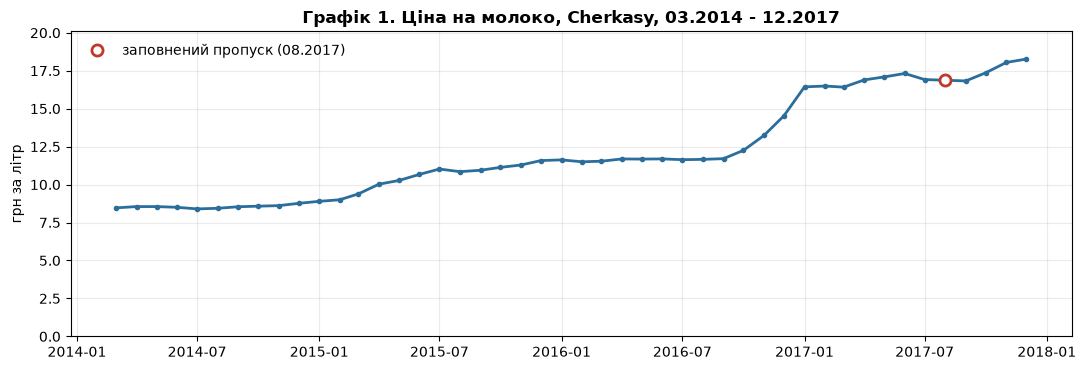

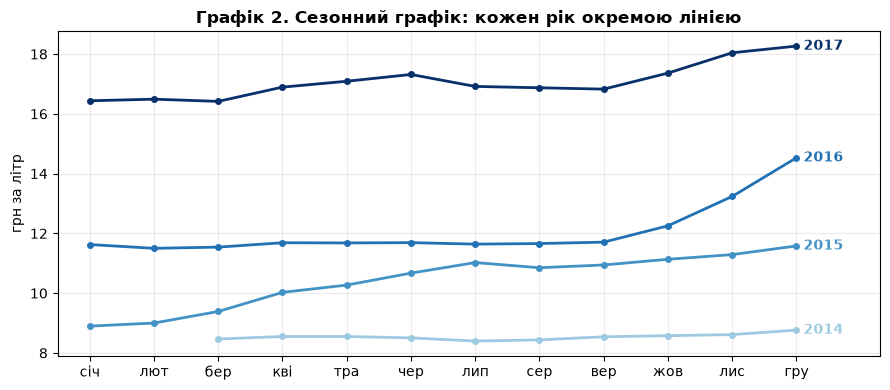

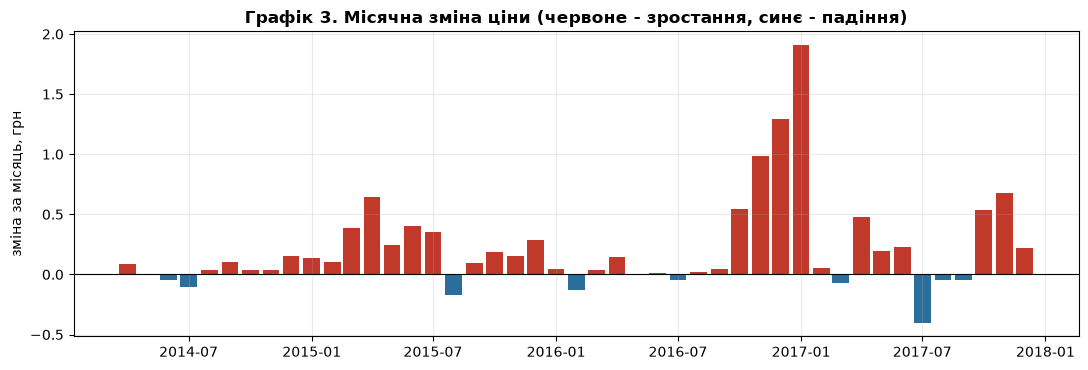

найбільші місячні прирости:
дата
2017-01-01    1.91
2016-12-01    1.29
2016-11-01    0.98
2017-11-01    0.68
2015-04-01    0.64

подорожчання за весь період: у 2.16 раза (у гривні, номінально)
курс грн/євро: 10.02 -> 27.53 (у 2.75 раза)
ціна в євро:   0.845 -> 0.664 євро/л (зміна у 0.79 раза)


In [5]:
# Завдання 3. Візуальна розвідка

# Графік 1. Як змінювався рівень ціни? Лінія з точками, вісь Y від нуля
fig, ax = plt.subplots()
ax.plot(y.index, y.values, lw=2, color='#2C6E9B', marker='o', ms=3)
ax.plot(gap, y[gap], 'o', ms=8, mfc='white', mec='#C0392B', mew=2, label='заповнений пропуск (08.2017)')
ax.set_ylim(0, y.max() * 1.1)
ax.set_ylabel('грн за літр')
ax.set_title(f'Графік 1. Ціна на {GOOD_UA}, {MARKET}, 03.2014 - 12.2017', fontweight='bold')
ax.legend(frameon=False)
plt.tight_layout(); plt.show()

# Графік 2. Чи повторюється щось щороку? Сезонний графік: X = місяць, лінія = рік
fig, ax = plt.subplots(figsize=(9, 4))
colors = ['#9ECAE1', '#4292C6', '#2171B5', '#08306B']   # послідовна палітра: світліше = раніше
for yr, c in zip(range(2014, 2018), colors):
    part = y[str(yr)]
    ax.plot(part.index.month, part.values, marker='o', ms=4, lw=2, color=c)
    ax.annotate(str(yr), xy=(part.index.month[-1], part.values[-1]), xytext=(5, 0),
                textcoords='offset points', color=c, fontweight='bold', va='center')
ax.set_xticks(range(1, 13))
ax.set_xticklabels(['січ', 'лют', 'бер', 'кві', 'тра', 'чер', 'лип', 'сер', 'вер', 'жов', 'лис', 'гру'])
ax.set_xlim(0.5, 13.3)
ax.set_ylabel('грн за літр')
ax.set_title('Графік 2. Сезонний графік: кожен рік окремою лінією', fontweight='bold')
plt.tight_layout(); plt.show()

# Графік 3. Коли саме ціна рухалась найсильніше? Місячний приріст, стовпчики від нуля
dy = y.diff()
fig, ax = plt.subplots()
ax.bar(dy.index, dy.values, width=25,
       color=np.where(dy > 0, '#C0392B', '#2C6E9B'))
ax.axhline(0, color='k', lw=.8)
ax.set_ylabel('зміна за місяць, грн')
ax.set_title('Графік 3. Місячна зміна ціни (червоне - зростання, синє - падіння)', fontweight='bold')
plt.tight_layout(); plt.show()

print('найбільші місячні прирости:')
print(dy.sort_values(ascending=False).head(5).round(2).to_string())
print()
print('подорожчання за весь період: у %.2f раза (у гривні, номінально)' % (y.iloc[-1] / y.iloc[0]))

# та сама ціна в євро: чи подорожчало молоко, чи подешевшала гривня?
rates = pd.read_csv('курс_євро_1990_2021.csv')
rates['дата'] = pd.to_datetime(dict(year=rates['рік'], month=rates['місяць'], day=1))
uah_eur = rates.set_index('дата')['грн_за_євро'].reindex(grid)
y_eur = y / uah_eur
print('курс грн/євро: %.2f -> %.2f (у %.2f раза)' % (uah_eur.iloc[0], uah_eur.iloc[-1], uah_eur.iloc[-1] / uah_eur.iloc[0]))
print('ціна в євро:   %.3f -> %.3f євро/л (зміна у %.2f раза)' % (y_eur.iloc[0], y_eur.iloc[-1], y_eur.iloc[-1] / y_eur.iloc[0]))

**Висновок до завдання 3:**

1. Питання й вибір форми:
   * **Графік 1 - "як змінювався рівень ціни?"** Лінія, бо ціна - рівень, а спостереження впорядковані в часі; лінія кодує величину положенням (найточніший канал за Клівлендом - Мак-Ґіллом) і показує послідовність. Маркери показують, що виміри щомісячні, а заповнений серпень 2017 виділено окремо, щоб не видавати його за вимір. Вісь Y **від нуля**, бо головне питання - "у скільки разів подорожчало", і тоді висота лінії пропорційна ціні (подорожчання в **2,16 раза** видно чесно).
   * **Графік 2 - "чи повторюється щось щороку?"** Сезонний графік: по X - місяць (циклічна шкала), кожен рік окрема лінія. Так сезонний малюнок порівнюється між роками положенням, а не вгадується на довгій лінії. Кольори - послідовна палітра одного відтінку, від світлого (2014) до темного (2017), бо роки впорядковані; підписи біля ліній замість легенди. Вісь Y тут **не від нуля**: питання про форму всередині року, а лінії зріз дозволений, і він видимий на осі.
   * **Графік 3 - "коли саме ціна рухалась найсильніше?"** Стовпчики місячної зміни. Тут стовпчики доречні, бо приріст - величина з осмисленим нулем (нуль = "ціна не змінилась"), і довжина стовпчика від нуля дорівнює зміні. Колір кодує лише знак (дві категорії), а не величину.
2. **Неочікувана знахідка:** майже весь 2016 рік ціна стояла на місці (11,5-11,7 грн), а потім за чотири місяці (09.2016 -> 01.2017) зросла з 11,71 до 16,44 грн, тобто на **40 %**. Друга знахідка - у гривні молоко подорожчало в 2,16 раза, але курс за цей час зріс з 10,02 до 27,53 грн/€, і **в євро літр молока подешевшав на 21 %** (0,85 -> 0,66 €). Тобто більша частина "подорожчання" - це знецінення гривні, а не зміна вартості самого молока, і без дефлятора відповідь "подорожчало в 2,16 раза" описує передусім курс. Найбільші місячні прирости - січень 2017 (+1,91), грудень 2016 (+1,29) і листопад 2016 (+0,98). До побудови графіків я очікувала рівномірне зростання через інфляцію, а не один стрибок. Крім того, на графіку 2 видно, що в кожному році ціна росте саме в жовтні - січні, а влітку майже стоїть.

## Завдання 4. Розкладання на складові

Розкладіть ряд на тренд, сезонну складову та залишок методом STL із періодом 12.

**У звіті наведіть:**
1. чотирипанельний графік розкладання;
2. числові значення сили сезонності $F_S$ та сили тренду $F_T$;
3. **висновок: чи є у вашому ряді сезонність**, із посиланням на порогове значення.

> 💡 **Підказка.** STL поверне сезонну складову завжди. Ваше завдання — вирішити, чи вона означає щось, а не чи вона є.

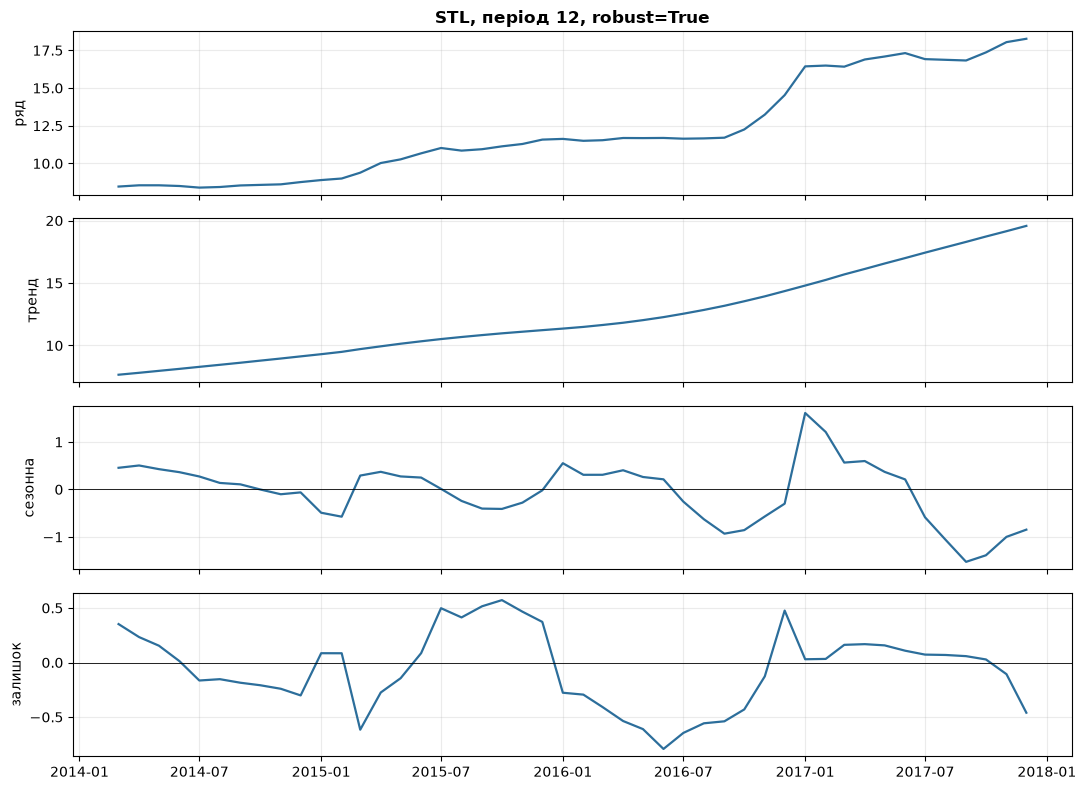

F_S (сила сезонності) = 0.764
F_T (сила тренду)     = 0.990

розмах сезонної складової за роками, грн:
дата
2014    0.61
2015    0.94
2016    1.48
2017    3.13

F_S на ряді 03.2014 - 12.2016 (без 2017 року) = 0.508

F_S для log(ціни) (мультиплікативна модель) = 0.348
розмах сезонної складової log за роками (≈ частка від рівня): [10.8, 11.6, 12.7, 19.3] %


In [6]:
# Завдання 4. Розкладання на складові
stl = STL(y, period=12, robust=True).fit()
T, S, R = stl.trend, stl.seasonal, stl.resid

fig, axes = plt.subplots(4, 1, figsize=(11, 8), sharex=True)
for ax, part, name in zip(axes, [y, T, S, R], ['ряд', 'тренд', 'сезонна', 'залишок']):
    ax.plot(part.index, part.values, lw=1.6, color='#2C6E9B')
    ax.set_ylabel(name)
axes[2].axhline(0, color='k', lw=.6); axes[3].axhline(0, color='k', lw=.6)
axes[0].set_title('STL, період 12, robust=True', fontweight='bold')
plt.tight_layout(); plt.show()

F_S = max(0, 1 - R.var() / (S + R).var())
F_T = max(0, 1 - R.var() / (T + R).var())
print('F_S (сила сезонності) = %.3f' % F_S)
print('F_T (сила тренду)     = %.3f' % F_T)

# перевірка стійкості: як змінюється амплітуда сезонної складової з року в рік
amp = S.groupby(S.index.year).agg(lambda x: x.max() - x.min())
print()
print('розмах сезонної складової за роками, грн:')
print(amp.round(2).to_string())

# а якщо прибрати 2017 рік (після стрибка)?
stl_pre = STL(y[:'2016-12'], period=12, robust=True).fit()
F_S_pre = max(0, 1 - stl_pre.resid.var() / (stl_pre.seasonal + stl_pre.resid).var())
print()
print('F_S на ряді 03.2014 - 12.2016 (без 2017 року) = %.3f' % F_S_pre)

# розмах коливань росте разом із рівнем -> перевіряємо мультиплікативну модель через логарифм
stl_log = STL(np.log(y), period=12, robust=True).fit()
F_S_log = max(0, 1 - stl_log.resid.var() / (stl_log.seasonal + stl_log.resid).var())
amp_log = stl_log.seasonal.groupby(stl_log.seasonal.index.year).agg(lambda x: x.max() - x.min())
print()
print('F_S для log(ціни) (мультиплікативна модель) = %.3f' % F_S_log)
print('розмах сезонної складової log за роками (≈ частка від рівня):', (amp_log * 100).round(1).tolist(), '%')

**Висновок до завдання 4:**

1. Чотирипанельний графік наведено вище (ряд, тренд, сезонна складова, залишок).
2. **F_S = 0,764**, **F_T = 0,990**.
3. Формально **F_S = 0,76 > 0,3**, і навіть > 0,7, тобто за шкалою з лекції сезонність "домінує". Але я перевірила, чи цьому можна вірити:
   * розмах сезонної складової росте з року в рік: 0,61 -> 0,94 -> 1,48 -> **3,13** грн, тобто разом із рівнем ціни. За теорією це ознака **мультиплікативної** моделі (розмах пропорційний рівню), а адитивний STL у такому разі завищує сезонну складову. Крім того, STL "затягнув" частину стрибка 10.2016 - 01.2017 у сезонну складову, бо стрибок припав на ті самі місяці, де ціна росте щороку;
   * без 2017 року (ряд 03.2014 - 12.2016) **F_S = 0,51**;
   * STL на **логарифмі** ціни (мультиплікативна модель): **F_S = 0,35**, а розмах сезонної складової відносно рівня майже сталий (близько 11-13 % у 2014-2016, 19 % у 2017 через стрибок).

   **Висновок: сезонність у ряді є, але слабка** - F_S = 0,35 у правильній (мультиплікативній) формі, тобто в межах 0,3-0,5, де її варто враховувати лише за змістовних підстав. Така підстава є: ціна молока росте восени й узимку (жовтень - січень), коли надої менші, а влітку стоїть - це видно на графіку 2 в кожному році. Значення 0,76 з адитивного STL завищене двома причинами: ростом рівня і зміною режиму в кінці 2016 року (завдання 8). Тренд дуже сильний (F_T = 0,99): майже вся мінливість ряду - це зростання рівня. Обмеження: на 46 точках (3,8 циклу) кожен сезонний коефіцієнт оцінено лише з 3-4 значень.

## Завдання 5. Стаціонарність

Побудуйте ACF і PACF вихідного ряду та його першої різниці. Застосуйте тести ADF і KPSS до обох.

**У звіті наведіть:**
1. графіки ACF і PACF до та після диференціювання;
2. таблицю з $p$-значеннями обох тестів для обох рядів;
3. висновок про стаціонарність **із зазначенням, узгоджуються тести між собою чи ні**;
4. якщо не узгоджуються — ваше пояснення, чому.

> 💡 **Підказка.** Нульові гіпотези ADF і KPSS протилежні. Перш ніж писати висновок, перевірте, що ви не переплутали напрямок.

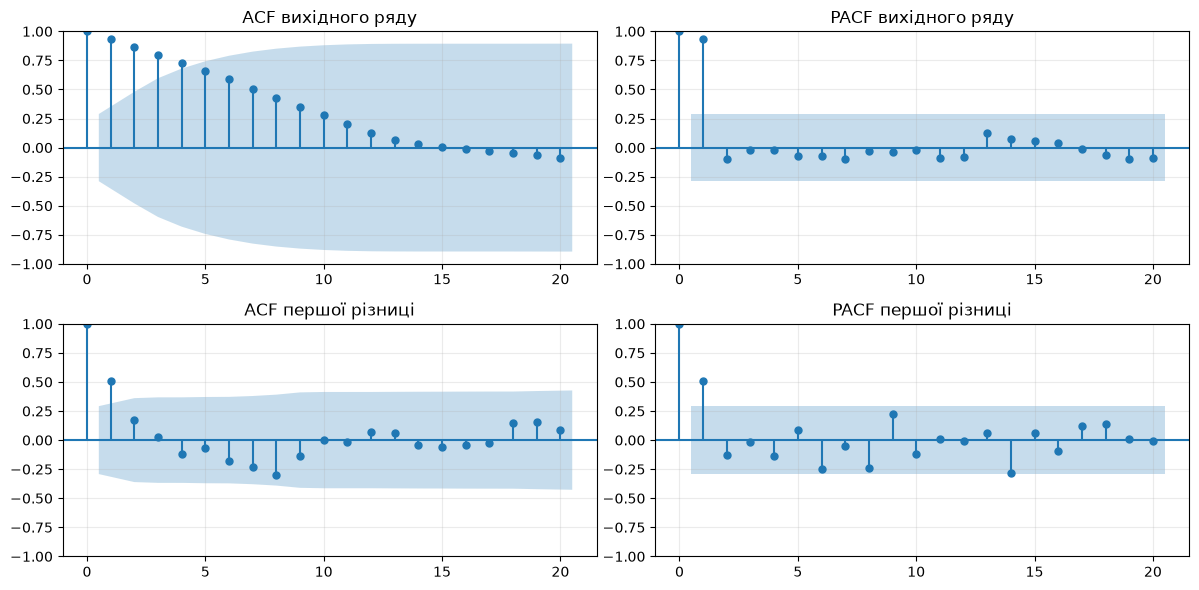

,ряд,ADF p,ADF каже,KPSS p,KPSS каже
0,вихідний ряд,0.9594,нестаціонарний,0.01,нестаціонарний
1,перша різниця,0.0043,стаціонарний,0.10,стаціонарний


(KPSS повертає p лише в межах 0.01 - 0.10; 0.01 означає "менше за 0.01", 0.1 - "більше за 0.1")
довірча межа для ACF різниці: ±0.29


In [7]:
# Завдання 5. Стаціонарність
d1 = y.diff().dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 6))
plot_acf(y, lags=20, ax=axes[0, 0]);  axes[0, 0].set_title('ACF вихідного ряду')
plot_pacf(y, lags=20, ax=axes[0, 1], method='ywm'); axes[0, 1].set_title('PACF вихідного ряду')
plot_acf(d1, lags=20, ax=axes[1, 0]); axes[1, 0].set_title('ACF першої різниці')
plot_pacf(d1, lags=20, ax=axes[1, 1], method='ywm'); axes[1, 1].set_title('PACF першої різниці')
plt.tight_layout(); plt.show()

rows = []
for name, x in [('вихідний ряд', y), ('перша різниця', d1)]:
    p_adf = adfuller(x, autolag='AIC')[1]
    p_kpss = kpss(x, regression='c', nlags='auto')[1]
    adf_says = 'стаціонарний' if p_adf < .05 else 'нестаціонарний'
    kpss_says = 'нестаціонарний' if p_kpss < .05 else 'стаціонарний'
    rows.append([name, round(p_adf, 4), adf_says, round(p_kpss, 4), kpss_says])
tests = pd.DataFrame(rows, columns=['ряд', 'ADF p', 'ADF каже', 'KPSS p', 'KPSS каже'])
display(tests)
print('(KPSS повертає p лише в межах 0.01 - 0.10; 0.01 означає "менше за 0.01", 0.1 - "більше за 0.1")')
print('довірча межа для ACF різниці: ±%.2f' % (1.96 / np.sqrt(len(d1))))

**Висновок до завдання 5:**

1. Графіки ACF і PACF наведено вище. Вихідний ряд: ACF спадає дуже повільно, майже лінійно (0,94; 0,87; 0,80; ...), PACF має один великий сплеск на лагу 1 (0,94) - класична ознака того, що потрібне диференціювання. Перша різниця: ACF значуща лише на лагу 1 (0,51 при межі ±0,29; лаг 8 = -0,30 на самій межі), PACF значуща лише на лагу 1 (0,51).
2. Таблиця p-значень:

| ряд | ADF p | KPSS p |
|---|---|---|
| вихідний | 0,959 | < 0,01 |
| перша різниця | 0,004 | > 0,10 |
3. Нагадую напрямок: в ADF H₀ - "ряд **не**стаціонарний", у KPSS H₀ - "ряд стаціонарний".
   * Вихідний ряд: ADF не відкидає H₀ (p = 0,96 > 0,05) -> нестаціонарний; KPSS відкидає H₀ (p < 0,01) -> нестаціонарний. **Тести узгоджуються: ряд нестаціонарний.**
   * Перша різниця: ADF відкидає H₀ (p = 0,004) -> стаціонарна; KPSS не відкидає H₀ (p > 0,10) -> стаціонарна. **Тести узгоджуються: перша різниця стаціонарна.**

   Отже, ряд інтегрований першого порядку, **d = 1**, друга різниця не потрібна.
4. Розбіжності немає. (KPSS у statsmodels повертає p лише в межах 0,01-0,10, тому точні значення "< 0,01" і "> 0,10" - це межі таблиці, а не реальні p, але висновок від цього не змінюється.)

## Завдання 6. Базисні прогнози та ретроспективна перевірка

Побудуйте **чотири** базисні прогнози: наївний, сезонний наївний, середнє та дрейф.
Оцініть їх **ретроспективною перевіркою з рухомим початком**: **7 фолдів по 3 кроки**,
навчальна частина розширюється.

**У звіті наведіть:**
1. таблицю MAE, RMSE і MAPE для всіх чотирьох базисів;
2. який базис виявився найкращим і **чому саме він** — поясніть через властивості вашого ряду;
3. для порівняння: ту саму оцінку, зроблену звичайним випадковим поділом 75/25, і **у скільки разів** вона відрізняється.

> 💡 **Підказка.** Кількість фолдів і кроків задана жорстко — у Частині 2 вона має збігтися з налаштуваннями Orange.

In [8]:
# Завдання 6. Базисні прогнози та ретроспективна перевірка
N_FOLDS, H = 7, 3
v = y.values
n = len(v)

def forecast(train, h, kind):
    """Базисні прогнози на h кроків за навчальною частиною train (numpy-масив)."""
    if kind == 'наївний':
        return np.repeat(train[-1], h)
    if kind == 'сезонний наївний':
        return np.array([train[len(train) - 12 + i] for i in range(h)])
    if kind == 'середнє':
        return np.repeat(train.mean(), h)
    if kind == 'дрейф':
        slope = (train[-1] - train[0]) / (len(train) - 1)
        return train[-1] + slope * np.arange(1, h + 1)
    if kind.startswith('ARIMA'):
        order = tuple(int(c) for c in kind[6:-1].split(','))   # 'ARIMA(1,1,1)' -> (1, 1, 1)
        return ARIMA(train, order=order).fit().forecast(h)
    raise ValueError(kind)

def rolling_origin(kind):
    """Фолди як в Orange: фолд f навчається на v[:-3f] і прогнозує наступні 3 точки.
    Повертає факт і прогноз у хронологічному порядку (f = 7, ..., 1)."""
    true, pred = [], []
    for f in range(N_FOLDS, 0, -1):
        train_end = n - H * f
        true.extend(v[train_end:train_end + H])
        pred.extend(forecast(v[:train_end], H, kind))
    return np.array(true), np.array(pred)

def metrics(true, pred):
    e = true - pred
    return dict(MAE=np.mean(np.abs(e)),
                RMSE=np.sqrt(np.mean(e ** 2)),
                MAPE=np.mean(np.abs(e / true)) * 100)

print('фолди (навчання -> перевірка):')
for f in range(N_FOLDS, 0, -1):
    te = n - H * f
    print(f'  f={f}: навчання {y.index[0]:%m.%Y}-{y.index[te-1]:%m.%Y} ({te} міс.)'
          f' -> перевірка {y.index[te]:%m.%Y}-{y.index[te+H-1]:%m.%Y}')

baselines = ['наївний', 'сезонний наївний', 'середнє', 'дрейф']
roll = pd.DataFrame({k: metrics(*rolling_origin(k)) for k in baselines}).T
print()
print('Рухомий початок, 7 фолдів по 3 кроки (MAE і RMSE - грн, MAPE - %):')
display(roll.round(3).sort_values('MAE'))

# Порівняння: випадковий поділ 75/25, усереднений по 200 розбиттях.
# Навчальні точки беруться з усього періоду, тому базиси "бачать" майбутнє:
# прогноз для тестової точки t будується з найближчої навчальної точки до t,
# а середнє і нахил дрейфу - з усієї навчальної частини, зокрема пізнішої за t.
rng = np.random.default_rng(42)
def random_split_eval(kind, n_rep=200):
    res = []
    for _ in range(n_rep):
        idx = rng.permutation(np.arange(12, n))   # з 12-ї точки, щоб був сезонний наївний
        test = np.sort(idx[:int(round(.25 * len(idx)))])
        train = np.setdiff1d(np.arange(n), test)
        true, pred = [], []
        for t in test:
            prev = train[train < t]
            if kind == 'наївний':
                p = v[prev[-1]]
            elif kind == 'сезонний наївний':
                p = v[t - 12] if (t - 12) in train else v[prev[-1]]
            elif kind == 'середнє':
                p = v[train].mean()
            elif kind == 'дрейф':
                slope = (v[train[-1]] - v[train[0]]) / (train[-1] - train[0])
                p = v[prev[-1]] + slope * (t - prev[-1])
            true.append(v[t]); pred.append(p)
        res.append(metrics(np.array(true), np.array(pred)))
    return pd.DataFrame(res).mean()

rand = pd.DataFrame({k: random_split_eval(k) for k in baselines}).T
cmp = pd.DataFrame({'MAE рухомий початок': roll['MAE'],
                    'MAE випадковий 75/25': rand['MAE']})
cmp['у скільки разів'] = cmp['MAE рухомий початок'] / cmp['MAE випадковий 75/25']
print('Порівняння з випадковим поділом:')
display(cmp.round(3).sort_values('MAE рухомий початок'))

фолди (навчання -> перевірка):
  f=7: навчання 03.2014-03.2016 (25 міс.) -> перевірка 04.2016-06.2016
  f=6: навчання 03.2014-06.2016 (28 міс.) -> перевірка 07.2016-09.2016
  f=5: навчання 03.2014-09.2016 (31 міс.) -> перевірка 10.2016-12.2016
  f=4: навчання 03.2014-12.2016 (34 міс.) -> перевірка 01.2017-03.2017
  f=3: навчання 03.2014-03.2017 (37 міс.) -> перевірка 04.2017-06.2017
  f=2: навчання 03.2014-06.2017 (40 міс.) -> перевірка 07.2017-09.2017
  f=1: навчання 03.2014-09.2017 (43 міс.) -> перевірка 10.2017-12.2017

Рухомий початок, 7 фолдів по 3 кроки (MAE і RMSE - грн, MAPE - %):


,MAE,RMSE,MAPE
дрейф,0.737,0.975,4.769
наївний,0.846,1.147,5.361
сезонний наївний,3.451,3.936,21.483
середнє,4.353,4.763,27.552


Порівняння з випадковим поділом:


,MAE рухомий початок,MAE випадковий 75/25,у скільки разів
дрейф,0.737,0.351,2.097
наївний,0.846,0.407,2.080
сезонний наївний,3.451,2.607,1.324
середнє,4.353,2.376,1.832


**Висновок до завдання 6:**

1. Рухомий початок, 7 фолдів по 3 кроки, навчальна частина розширюється (від 25 до 43 місяців), перевіряються останні 21 місяць (04.2016 - 12.2017):

| базис | MAE, грн | RMSE, грн | MAPE, % |
|---|---|---|---|
| дрейф | **0,737** | **0,975** | **4,77** |
| наївний | 0,846 | 1,147 | 5,36 |
| сезонний наївний | 3,451 | 3,936 | 21,48 |
| середнє | 4,353 | 4,763 | 27,55 |
2. **Найкращий - дрейф** за всіма трьома метриками, наївний близький до нього. Це прямо випливає з властивостей ряду: у ньому сильний висхідний тренд (F_T = 0,99) і він нестаціонарний з d = 1, тобто найкращий прогноз - "останнє значення", а дрейф ще й додає середній нахил ряду (ціна зростала в середньому на 0,2 грн за місяць). Середнє програє в 5-6 разів, бо тягне прогноз до старих низьких цін 2014-2015 років. Сезонний наївний теж дуже поганий, хоча слабка сезонність є: він копіює ціну рік тому, а за рік рівень виріс на кілька гривень - тренд тут значно сильніший за сезонні коливання (кілька десятків копійок).
3. Випадковий поділ 75/25 (середнє по 200 розбиттях) дає MAE дрейфу **0,351** замість 0,737 і наївного **0,407** замість 0,846, тобто **занижує помилку приблизно у 2,1 раза**. Для середнього різниця в 1,8 раза, для сезонного наївного в 1,3 раза. Причина - витік даних: при випадковому поділі тестова точка оточена навчальними з обох боків, найближча відома ціна майже завжди за 1 місяць, а середнє й нахил рахуються з урахуванням майбутніх точок. Це вже не прогноз на 3 місяці вперед, а інтерполяція.

## Завдання 7. Модель ARIMA

Побудуйте модель ARIMA і оцініть її **на тих самих 7 фолдах по 3 кроки**.

Обов'язково використайте порядок **(1, 1, 1)** — саме його ви відтворюватимете в Orange.
Додатково визначте, який порядок $(p, d, q)$ ви обрали б **за виглядом ACF і PACF** із завдання 5.

**У звіті наведіть:**
1. MAE, RMSE і MAPE моделі ARIMA(1,1,1) на рухомому початку;
2. обґрунтування порядку, який ви обрали б самостійно, з посиланням на конкретні лаги;
3. **порівняння з найкращим базисом із завдання 6** — і прямий висновок, чи має ця модель право на існування;
4. графік залишків моделі та висновок, чи лишилася в них структура.

> 💡 **Підказка.** Якщо ARIMA програла базису — це законний результат, а не помилка. Напишіть про це прямо.

,MAE,RMSE,MAPE
"ARIMA(1,1,1)",0.706,0.956,4.496
дрейф,0.737,0.975,4.769
наївний,0.846,1.147,5.361
сезонний наївний,3.451,3.936,21.483
середнє,4.353,4.763,27.552


найкращий базис: дрейф, MAE = 0.737
ARIMA(1,1,1):          MAE = 0.706  (виграш 4.1%)


,MAE дрейф,MAE ARIMA
f=7,0.123,0.132
f=6,0.260,0.043
f=5,1.417,1.596
f=4,1.550,0.662
f=3,0.242,0.748
f=2,0.899,0.658
f=1,0.666,1.106


AIC на повному ряді: {'(1, 1, 0)': 37.71, '(0, 1, 1)': 40.49, '(1, 1, 1)': 39.57, '(2, 1, 0)': 39.6}


ARIMA(1,1,0) на тих самих фолдах: {'MAE': 0.729, 'RMSE': 0.982, 'MAPE': 4.617}

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.5509      0.290      1.897      0.058      -0.018       1.120
ma.L1          0.1047      0.490      0.213      0.831      -0.857       1.066
sigma2         0.1221      0.017      7.315      0.000       0.089       0.155


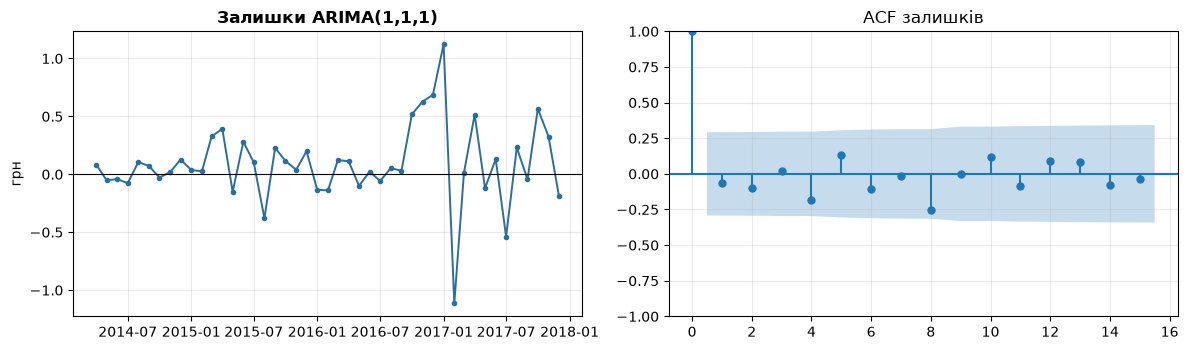

найбільші за модулем залишки:
дата
2017-01-01    1.122
2017-02-01    1.115
2016-12-01    0.686
2016-11-01    0.628
тест Льюнга-Бокса (H0: залишки - білий шум):


,lb_stat,lb_pvalue
6,4.0353,0.6719
12,9.6282,0.6485


In [9]:
# Завдання 7. Модель ARIMA
true_ar, pred_ar = rolling_origin('ARIMA(1,1,1)')
m_arima = metrics(true_ar, pred_ar)

summary = pd.concat([roll, pd.DataFrame({'ARIMA(1,1,1)': m_arima}).T])
display(summary.round(3).sort_values('MAE'))

best = roll['MAE'].idxmin()
print(f'найкращий базис: {best}, MAE = {roll.loc[best, "MAE"]:.3f}')
print(f'ARIMA(1,1,1):          MAE = {m_arima["MAE"]:.3f}  '
      f'(виграш {100 * (1 - m_arima["MAE"] / roll.loc[best, "MAE"]):.1f}%)')

# помилки по фолдах - чи виграш стабільний
_, pred_best = rolling_origin(best)
by_fold = pd.DataFrame({
    'MAE ' + best: np.abs(true_ar - pred_best).reshape(N_FOLDS, H).mean(axis=1),
    'MAE ARIMA':   np.abs(true_ar - pred_ar).reshape(N_FOLDS, H).mean(axis=1)},
    index=[f'f={f}' for f in range(N_FOLDS, 0, -1)])
display(by_fold.round(3))

# кандидати порядку за ACF/PACF першої різниці + порівняння за AIC на повному ряді
aic = {o: ARIMA(v, order=o).fit().aic for o in [(1, 1, 0), (0, 1, 1), (1, 1, 1), (2, 1, 0)]}
print('AIC на повному ряді:', {str(k): round(float(a), 2) for k, a in aic.items()})
m_110 = metrics(*rolling_origin('ARIMA(1,1,0)'))
print('ARIMA(1,1,0) на тих самих фолдах:', {k: round(float(x), 3) for k, x in m_110.items()})

# залишки моделі на повному ряді
full = ARIMA(y, order=(1, 1, 1)).fit()
print()
print(full.summary().tables[1])
resid = full.resid[1:]   # перший залишок - це просто перше значення ряду, відкидаємо

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(resid.index, resid.values, lw=1.4, marker='o', ms=3, color='#2C6E9B')
axes[0].axhline(0, color='k', lw=.8)
axes[0].set_title('Залишки ARIMA(1,1,1)', fontweight='bold'); axes[0].set_ylabel('грн')
plot_acf(resid, lags=15, ax=axes[1]); axes[1].set_title('ACF залишків')
plt.tight_layout(); plt.show()

print('найбільші за модулем залишки:')
print(resid.abs().sort_values(ascending=False).head(4).round(3).to_string())
lb = acorr_ljungbox(resid, lags=[6, 12])
print('тест Льюнга-Бокса (H0: залишки - білий шум):')
display(lb.round(4))

**Висновок до завдання 7:**

1. ARIMA(1,1,1) на тих самих 7 фолдах по 3 кроки: **MAE = 0,706 грн, RMSE = 0,956 грн, MAPE = 4,50 %**.
2. За ACF і PACF я б обрала **ARIMA(1,1,0)**: d = 1 з тестів ADF/KPSS (завдання 5); у першої різниці PACF обривається після лагу 1 (0,51, далі все в межах ±0,29), а ACF спадає поступово (0,51 -> 0,17 -> 0,02), що відповідає AR(1). Перевірка за AIC це підтверджує: (1,1,0) - **37,7**, (1,1,1) - 39,6, (2,1,0) - 39,6, (0,1,1) - 40,5. До того ж у моделі (1,1,1) коефіцієнт MA незначущий (ma.L1 = 0,10, p = 0,83), тобто MA-частина зайва. На фолдах ARIMA(1,1,0) дає MAE 0,729 - майже те саме.
3. **Порівняння з найкращим базисом (дрейф, MAE 0,737):** ARIMA виграє лише **4,1 %** (3 копійки на літр), і по фолдах виграє лише в 3 з 7 (виграш у середньому дає переважно один фолд 01-03.2017). На 21 перевіреній точці така різниця не є переконливою - фактично модель і дрейф рівноцінні. Прямий висновок: ARIMA(1,1,1) **не має переваги, яка виправдовувала б її складність**; для цього ряду достатньо дрейфу, а якщо брати ARIMA, то простішу (1,1,0). Найбільша помилка обох методів - на фолді 10-12.2016, коли почався стрибок (MAE 1,42 у дрейфу і 1,60 в ARIMA): жоден метод, що екстраполює минуле, не міг його передбачити.
4. Графік залишків наведено вище. ACF залишків - усі лаги в довірчих межах, тест Льюнга-Бокса p = 0,67 (лаг 6) і 0,65 (лаг 12), тобто H₀ "залишки - білий шум" не відкидається: **лінійної структури в залишках не лишилось**. Але залишки неоднорідні: чотири найбільші за модулем залишки - 01.2017 (1,12 грн), 02.2017 (1,12), 12.2016 (0,69) і 11.2016 (0,63), тобто всі припадають на стрибок, при типовому розмірі залишку близько 0,35 грн (σ² = 0,122). Отже, модель описує "звичайну" динаміку, а зміну режиму вона сприймає як великі випадкові шоки.

## Завдання 8. Точка зміни режиму

Знайдіть у своєму ряді точку, після якої змінюється **рівень** ряду.
Скористайтеся скануванням: для кожної кандидатної дати порівняйте середні до і після
та оберіть дату з найбільшою t-статистикою.

**У звіті наведіть:**
1. графік ряду з позначеною знайденою датою;
2. дату, значення t-статистики, середні рівні до і після;
3. **чи є ця точка значущою** — і якщо ні, так і напишіть;
4. чим знайдена точка відрізняється від звичайного сезонного сплеску у вашому ряді.

> 💡 **Підказка.** Не плутайте зсув рівня з сезонним піком. Якщо «аномалії» повторюються щороку в ті самі місяці — це сезон.

знайдена точка (перший місяць нового режиму): 01.2017


,|t|,p,середнє до,середнє після
дата,,,,
2017-01-01,20.382,0.0,10.448,17.078


p = 5.4e-24
кандидатів перевірено: 35 | поріг з поправкою Бонферроні: 0.00143


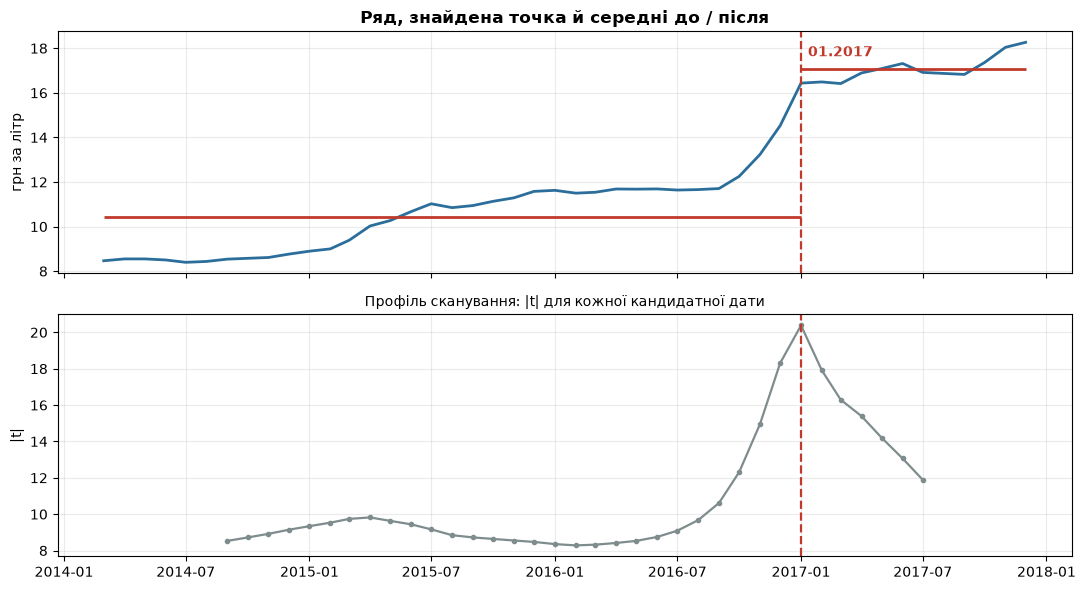

локально (6 міс. до / 6 міс. після): 12.50 -> 16.77 грн, t = 8.52, p = 0.00014
09.2014 -> 01.2015: 8.54 -> 8.90 (+0.36 грн); у липні 2015: 11.02
09.2015 -> 01.2016: 10.94 -> 11.63 (+0.68 грн); у липні 2016: 11.64
09.2016 -> 01.2017: 11.71 -> 16.44 (+4.73 грн); у липні 2017: 16.92


In [10]:
# Завдання 8. Точка зміни режиму
MIN_SEG = 6   # мінімум пів року з кожного боку
scan = []
for i in range(MIN_SEG, n - MIN_SEG + 1):
    before, after = v[:i], v[i:]
    t, p = stats.ttest_ind(before, after, equal_var=False)   # t-тест Велча
    scan.append((y.index[i], abs(t), p, before.mean(), after.mean()))
scan = pd.DataFrame(scan, columns=['дата', '|t|', 'p', 'середнє до', 'середнє після']).set_index('дата')
cp = scan['|t|'].idxmax()

print('знайдена точка (перший місяць нового режиму):', cp.strftime('%m.%Y'))
display(scan.loc[[cp]].round(3))
print('p = %.2g' % scan.loc[cp, 'p'])

# Bonferroni: ми перебрали багато дат, тому поріг треба ділити на їх кількість
print('кандидатів перевірено:', len(scan), '| поріг з поправкою Бонферроні: %.5f' % (.05 / len(scan)))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
axes[0].plot(y.index, y.values, lw=2, color='#2C6E9B')
axes[0].axvline(cp, color='#C0392B', lw=1.6, ls='--')
axes[0].hlines(scan.loc[cp, 'середнє до'], y.index[0], cp, color='#C0392B', lw=2)
axes[0].hlines(scan.loc[cp, 'середнє після'], cp, y.index[-1], color='#C0392B', lw=2)
axes[0].annotate(cp.strftime('%m.%Y'), xy=(cp, y.max()), xytext=(5, -10),
                 textcoords='offset points', color='#C0392B', fontweight='bold')
axes[0].set_ylabel('грн за літр')
axes[0].set_title('Ряд, знайдена точка й середні до / після', fontweight='bold')
axes[1].plot(scan.index, scan['|t|'], lw=1.6, color='#7F8C8D', marker='o', ms=3)
axes[1].axvline(cp, color='#C0392B', lw=1.6, ls='--')
axes[1].set_ylabel('|t|')
axes[1].set_title('Профіль сканування: |t| для кожної кандидатної дати', fontsize=10)
plt.tight_layout(); plt.show()

# Перевірка стійкості: локальне порівняння 6 місяців до проти 6 місяців після
# (менше залежить від загального тренду, ніж порівняння всього "до" з усім "після")
loc_before, loc_after = y[cp - pd.DateOffset(months=6):cp - pd.DateOffset(months=1)], y[cp:cp + pd.DateOffset(months=5)]
t_loc, p_loc = stats.ttest_ind(loc_before, loc_after, equal_var=False)
print('локально (6 міс. до / 6 міс. після): %.2f -> %.2f грн, t = %.2f, p = %.2g'
      % (loc_before.mean(), loc_after.mean(), abs(t_loc), p_loc))

# Чим відрізняється від сезонного сплеску: приріст жовтень -> січень у кожному році
for yr in (2014, 2015, 2016):
    a, b = y[f'{yr}-09-01'], y[f'{yr + 1}-01-01']
    after_summer = y[f'{yr + 1}-07-01']
    print(f'09.{yr} -> 01.{yr+1}: {a:.2f} -> {b:.2f} (+{b - a:.2f} грн); '
          f'у липні {yr+1}: {after_summer:.2f}')

**Висновок до завдання 8:**

1. Графік ряду з позначеною датою та профіль сканування наведено вище.
2. Перебрала 35 кандидатних дат (мінімум 6 місяців з кожного боку), t-тест Велча. Найбільша статистика - на **01.2017** (перший місяць нового рівня): **|t| = 20,4**, середнє до - **10,45 грн**, після - **17,08 грн**, p ≈ 5·10⁻²⁴.
3. Формально точка **значуща** навіть з поправкою Бонферроні на 35 перевірок (поріг 0,0014). Але p тут сильно занижене: t-тест вважає спостереження незалежними, а ряд має автокореляцію 0,94 і тренд - тому на профілі |t| великий майже для будь-якої дати (ряд просто росте). Тому я перевірила ще локально: 6 місяців до проти 6 місяців після - 12,50 -> 16,77 грн, t = 8,5, p = 1,4·10⁻⁴, теж нижче порогу. І головне - ряд **не повернувся** до попереднього рівня (у липні 2017 - 16,92 грн, у грудні - 18,27), тобто це не викид, а саме **зміна режиму**. Можливе зовнішнє пояснення - подвоєння мінімальної зарплати з 1 січня 2017 року (з 1600 до 3200 грн) і подорожчання сирого молока восени 2016-го; з даних це довести не можна, це лише гіпотеза.
4. **Відмінність від сезонного сплеску.** Ціна зростає у вересні - січні щороку: 2014/15 - на **+0,36 грн**, 2015/16 - на **+0,68 грн**, а 2016/17 - на **+4,73 грн**, тобто у 7-13 разів більше. Сезонний підйом має приблизно сталий розмір і повторюється в тих самих місяцях. Зсув 2016/17 стався в ті самі місяці, тому його легко сплутати з сезоном, але його розмір безпрецедентний і після нього рівень не повернувся. Саме тому STL частково записав його в сезонну складову і завищив F_S (завдання 4).

## Завдання 9. Рецензія на чужий аналіз

Відкрийте `ЛР4_помилковий_аналіз.ipynb`. Це звіт, зроблений на іншому ряді з того самого набору.
Він виконується без помилок і виглядає переконливо, але містить **методологічні помилки**.

**У звіті наведіть:**
1. перелік знайдених помилок — для кожної вкажіть номер клітинки, суть помилки й **чим вона небезпечна**;
2. для трьох найсерйозніших — як саме їх виправити.

> 💡 **Підказка.** Помилок щонайменше вісім. Шукайте не синтаксис, а порушення принципів роботи з часовими рядами.

In [11]:
# Завдання 9. Рецензія на чужий аналіз
# Рецензія письмова (див. висновок). Тут лише дві швидкі перевірки тверджень колеги на його ж ряді.
vin = prices[(prices['ринок'] == 'Vinnytsia') & (prices['товар'] == 'Buckwheat grits - Retail')].set_index('дата')['ціна'].reindex(grid)
lvi = prices[(prices['ринок'] == 'Lviv') & (prices['товар'] == 'Buckwheat grits - Retail')].set_index('дата')['ціна'].reindex(grid)
print('пропусків у його ряді на повній сітці:', vin.isna().sum(), '->', [d.strftime('%m.%Y') for d in vin[vin.isna()].index])
print('кореляція рівнів Вінниця-Львів:    r = %.3f' % vin.corr(lvi))
print('кореляція приростів Вінниця-Львів: r = %.3f' % vin.diff().corr(lvi.diff()))
vin_f = vin.interpolate()
print('ADF p на його ряді = %.3f (H0 - НЕстаціонарний, отже не відкидаємо = нестаціонарний)' % adfuller(vin_f, autolag='AIC')[1])
print('частка точок з |z| > 2: %d з %d' % (((vin_f - vin_f.mean()) / vin_f.std()).abs().gt(2).sum(), len(vin_f)))

пропусків у його ряді на повній сітці: 1 -> ['08.2017']
кореляція рівнів Вінниця-Львів:    r = 0.996
кореляція приростів Вінниця-Львів: r = 0.937
ADF p на його ряді = 0.348 (H0 - НЕстаціонарний, отже не відкидаємо = нестаціонарний)
частка точок з |z| > 2: 0 з 46


**Висновок до завдання 9:**

Номери клітинок - за порядком у зошиті, починаючи з 0.

| № | клітинка | помилка | чим небезпечна |
|---|---|---|---|
| 1 | [1], [3] | Ряд не приведено до повної місячної сітки; `isna()` на 45 рядках показує 0 пропусків, хоча 08.2017 відсутній. | Пропуск захований; `shift(12)`, `diff()`, STL з періодом 12 рахують позиції, а не місяці, тож після 07.2017 усе зсувається на місяць. |
| 2 | [5] | Висновок "подорожчала у 2,5 раза" з двох крайніх точок, без урахування девальвації гривні; "зниження купівельної спроможності" без даних про доходи. | Результат залежить від вибору кінців проміжку; висновок про добробут не випливає з даних про ціни. |
| 3 | [7] | MAE гречки й яловичини порівнюються напряму. | MAE в гривнях залежить від масштабу ціни (яловичина в рази дорожча), тому "гірше прогнозується" нічого не доводить; треба безрозмірну метрику (MAPE, MASE). |
| 4 | [9] | Кореляція **рівнів** двох зростаючих рядів (r = 0,996) і висновок "Львів **визначає** Вінницю". | Удавана регресія: два ряди з трендом корелюють за побудовою. Кореляція не означає причинності; спільна причина - загальна інфляція. (Кореляція приростів 0,94 - зв'язок, можливо, є, але напрямку вона не показує.) |
| 5 | [11] | "STL виділив сезонну складову, отже ряд сезонний" - без F_S. | STL повертає сезонну складову завжди; без F_S і порогу 0,3 висновок безпідставний, а далі на ньому будуються "сезонні моделі". |
| 6 | [13] | ADF прочитано навпаки: p = 0,233 > 0,05 -> H₀ не відкидається -> ряд **не**стаціонарний, а написано "стаціонарний". Немає KPSS. | Неправильний d, неправильна модель; з нестаціонарним рядом не працюють звичайні статистичні висновки. |
| 7 | [13] | Подвійне диференціювання "для надійності". | Передиференціювання збільшує дисперсію і може внести штучну від'ємну автокореляцію (характерна ознака - ρ₁ близько -0,5; тут -0,13, тобто ефект слабкий), але головне - d = 2 нічим не обґрунтоване: досить було перевірити першу різницю. |
| 8 | [15] | У тексті "два стандартні відхилення", у коді поріг 1,3; аномалії шукаються у вихідному ряді з трендом. | "Аномалії" - це просто 2014 рік (ціна нижча через тренд) і пік 2016; з порогом 2σ не знайшлося б жодної. Шукати треба в залишках після зняття тренду й сезонності. |
| 9 | [17] | Випадковий `train_test_split` для часового ряду. | Витік майбутнього в навчання, помилка систематично занижена (у моєму ряді приблизно в 2 рази). |
| 10 | [17] | `np.sort(y_te)` - факт відсортовано за значенням, а не за часом, і порівняно з прогнозом "від кінця" ряду. | MAE 8,73 порівнює непов'язані числа; метрика беззмістовна. |
| 11 | [17] | MAE сезонного наївного пораховано на всьому ряді, а не на тих самих тестових точках; наївного (y_{t-1}) базису немає; "висока точність" без відносної шкали. | Порівняння з базисом нечесне; 8,73 грн при ціні 7-18 грн - це помилка порядку 50-100 %, а не "висока точність". |
| 12 | [19] | Фінальний прогноз іншою моделлю ARIMA(2,2,1), яку не перевіряли; прогноз на 12.2018 = **8,95 грн**, тобто нижче за поточні 17,67, а висновок - "ціна продовжить зростати"; немає інтервалів. | Текст суперечить числу; модель не валідована; 12 кроків уперед без невизначеності. |
| 13 | [21] | Стовпчики зі зрізаною віссю Y (від min·0,995) на вибраних 6 місяцях. | Порушено принцип пропорційного чорнила, коефіцієнт брехні в десятки разів; зміна на копійки виглядає як "стрімке зростання"; плюс підбір вікна. |
| 14 | [22] | Загальні висновки повторюють усі попередні помилки як доведені факти. | Читач отримує впевнені висновки, жоден з яких не підтверджено. |

**Як виправити три найсерйозніші:**

* **Випадковий поділ (9-11).** Замінити на ретроспективну перевірку з рухомим початком (наприклад, 7 фолдів по 3 кроки, як у мене в завданні 6): навчати лише на минулому, прогнозувати наступні 3 місяці, на **тих самих** фолдах рахувати наївний, сезонний наївний, середнє й дрейф, і лише потім ARIMA. Порівнювати факт і прогноз у часовому порядку, без сортування.
* **Стаціонарність (6-7).** Правильно прочитати ADF (p = 0,23 -> нестаціонарний), додати KPSS, перевірити першу різницю обома тестами; якщо вона стаціонарна - d = 1, без другої різниці. Підбирати p, q за ACF/PACF першої різниці і AIC.
* **Сітка й пропуск (1).** Зробити `reindex` на `pd.date_range('2014-03-01', '2017-12-01', freq='MS')`, знайти пропуск 08.2017, пояснити його (немає даних по всьому набору) і заповнити лінійною інтерполяцією до будь-якого аналізу. Без цього всі подальші кроки з лагами працюють на неправильному ряді.

## Завдання 10. Експорт ряду для Orange

Збережіть підготовлений ряд у файл `ряд_для_orange.csv` **рівно у такому вигляді**:

| Стовпець | Тип | Зміст |
|---|---|---|
| `date` | текст у форматі `РРРР-ММ-ДД` | перше число місяця |
| `price` | число | ціна, пропуск уже заповнений |

Один рядок на місяць, 46 рядків плюс заголовок, роздільник — кома, кодування UTF-8.

**У звіті наведіть:**
1. підтвердження, що файл має 46 рядків даних і не містить порожніх значень.

> 💡 **Підказка.** Формат заданий жорстко: Orange має отримати **точно ті самі** дані, що й Python, інакше порівняння в Частині 2 втрачає сенс.

In [12]:
# Завдання 10. Експорт ряду для Orange
out = pd.DataFrame({'date': y.index.strftime('%Y-%m-%d'), 'price': y.values.round(4)})
out.to_csv('ряд_для_orange.csv', index=False, encoding='utf-8')

check = pd.read_csv('ряд_для_orange.csv')
print('рядків даних:', len(check), '| стовпці:', list(check.columns))
print('порожніх значень:', check.isna().sum().sum())
print('перший / останній рядок:', check.iloc[0].tolist(), check.iloc[-1].tolist())
print('серпень 2017:', check[check['date'] == '2017-08-01'].to_dict('records'))
with open('ряд_для_orange.csv', encoding='utf-8') as fh:
    print(''.join(fh.readlines()[:3]))

рядків даних: 46 | стовпці: ['date', 'price']
порожніх значень: 0
перший / останній рядок: ['2014-03-01', np.float64(8.4667)] ['2017-12-01', np.float64(18.2667)]
серпень 2017: [{'date': '2017-08-01', 'price': 16.8717}]
date,price
2014-03-01,8.4667
2014-04-01,8.55



**Висновок до завдання 10:**

Файл `ряд_для_orange.csv` записано й прочитано назад для перевірки: **46 рядків даних** + заголовок, стовпці `date` (текст РРРР-ММ-ДД, перше число місяця) і `price`, роздільник кома, UTF-8, **порожніх значень 0**. Серпень 2017 уже заповнений (16,8717). Тобто Orange отримує рівно той самий ряд `y`, на якому зроблено всю Частину 1.

---
# ЧАСТИНА 2. Той самий аналіз засобами Orange

*Виконується самостійно.*

Потрібен додаток **Timeseries**: у Orange відкрийте *Options → Add-ons…* і встановіть `Orange3-Timeseries`.

**Головна умова цієї частини:** Orange має отримати **ті самі дані** й **ті самі налаштування перевірки**,
що й Python у Частині 1. Тоді будь-яка розбіжність у числах пояснюється **лише означеннями метрик**,
а не різними даними чи різними моделями. Саме це вам і треба довести.

## Завдання 11. Потік опрацювання даних

Побудуйте в Orange потік:

`File` → `As Timeseries` → `Interpolate` → `Line Chart`

У віджеті **File** завантажте свій `ряд_для_orange.csv`; переконайтеся, що `date` розпізнано
як **time**, а `price` — як **numeric**. У віджеті **As Timeseries** оберіть `date` як часову змінну.

**У звіті наведіть:**
1. знімок екрана з побудованим потоком;
2. знімок `Line Chart` із вашим рядом;
3. підтвердження, що графік у Orange збігається з графіком із завдання 3.

> 💡 **Підказка.** Якщо `date` розпізнано як текст, поверніться до завдання 10 і перевірте формат дати.

In [13]:
# Завдання 11. Потік опрацювання даних
# Виконується в Orange. Знімки екрана: потік і Line Chart.

**Висновок до завдання 11:**

Потік (повний, разом із віджетами завдань 12-13):

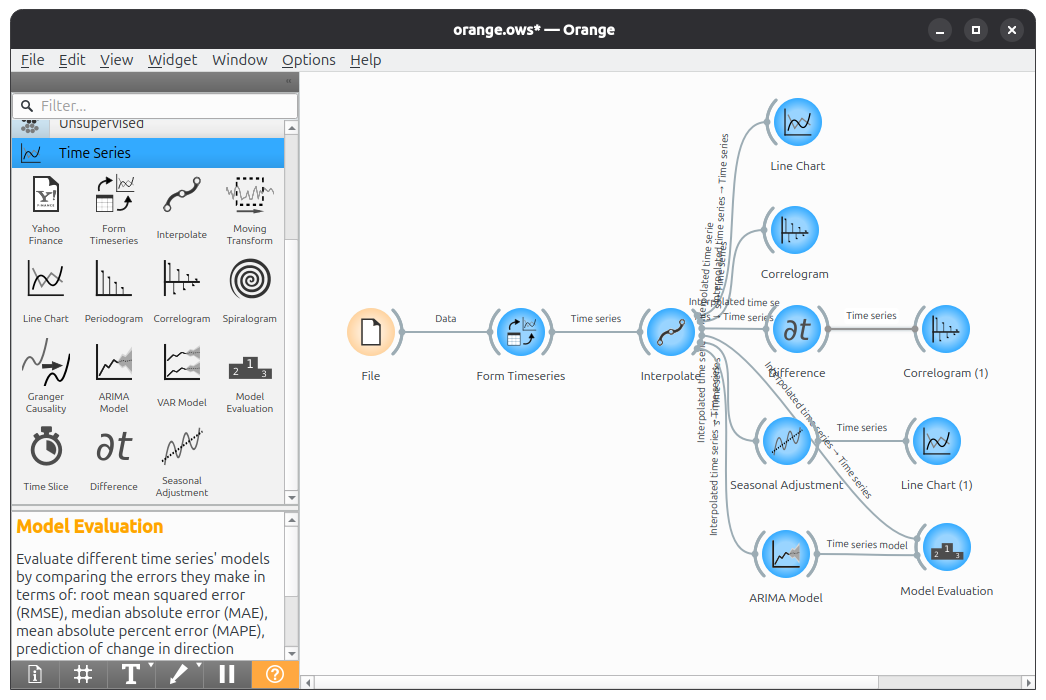

`Line Chart` з моїм рядом:

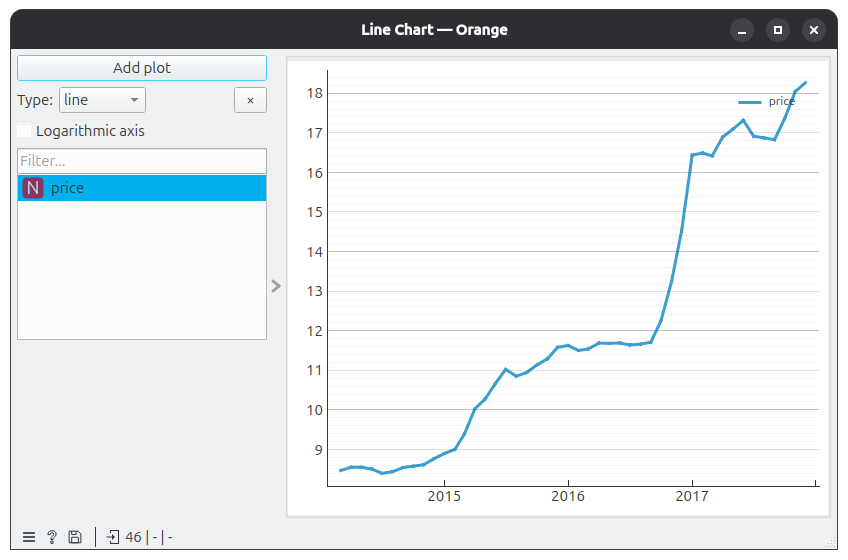

1. У віджеті File `date` розпізнано як **datetime (time)**, `price` - як **numeric**; ролі `price` я поставила **target**, бо без неї Model Evaluation далі пише "Data requires a target variable". Потік збережено у файлі `потік_orange.ows`.
2. **Графік у Orange збігається з графіком 1 із завдання 3:** рівень близько 8,5 грн у 2014 році, зростання 2015 року до 11,5 грн, майже рівна полиця 2016 року, стрибок 10.2016 - 01.2017 до 16,5 грн, спад улітку 2017 і 18,27 грн у грудні 2017. Пропуску за 08.2017 на графіку немає, бо він уже заповнений у файлі (16,87, лінійна інтерполяція), тож Interpolate нічого не змінює.

## Завдання 12. Автокореляція та диференціювання

Додайте до потоку віджети `Correlogram`, `Difference` та `Seasonal Adjustment`.

**У звіті наведіть:**
1. знімок корелограми;
2. зіставлення з ACF із завдання 5: **чи збігаються висновки** про значущі лаги;
3. знімок сезонно скоригованого ряду та порівняння з сезонною складовою STL із завдання 4.

> 💡 **Підказка.** Orange і statsmodels рахують автокореляцію однаково — якщо картина різна, перевірте, чи однакові дані на вході.

In [14]:
# Завдання 12. Автокореляція та диференціювання
# Корелограма Orange - знімок. Для зіставлення - ті самі числа ACF зі statsmodels:
from statsmodels.tsa.stattools import acf
acf_tbl = pd.DataFrame({'ACF ряду': acf(y, nlags=12), 'ACF різниці': acf(d1, nlags=12)}).iloc[1:]
acf_tbl.index.name = 'лаг'
display(acf_tbl.round(3).T)
print('довірча межа ±1.96/sqrt(n): ряд ±%.3f, різниця ±%.3f' % (1.96 / np.sqrt(len(y)), 1.96 / np.sqrt(len(d1))))

лаг,1,2,3,4,5,6,7,8,9,10,11,12
ACF ряду,0.938,0.867,0.798,0.731,0.660,0.586,0.505,0.426,0.350,0.279,0.203,0.125
ACF різниці,0.513,0.171,0.023,-0.115,-0.066,-0.180,-0.230,-0.301,-0.133,0.000,-0.013,0.073


довірча межа ±1.96/sqrt(n): ряд ±0.289, різниця ±0.292


**Висновок до завдання 12:**

Корелограма вихідного ряду і першої різниці (`Difference` -> `Correlogram`):

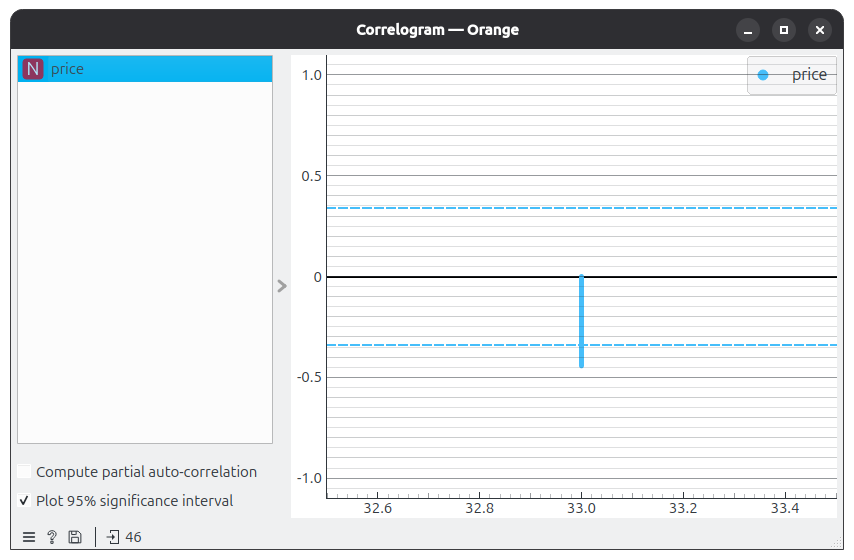

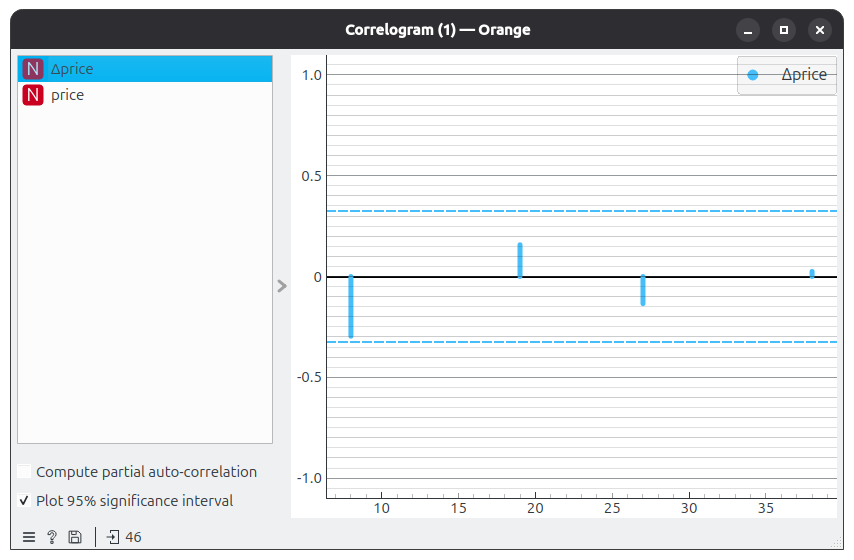

Сезонно скоригований ряд і сезонна складова (`Seasonal Adjustment`, період 12, additive):

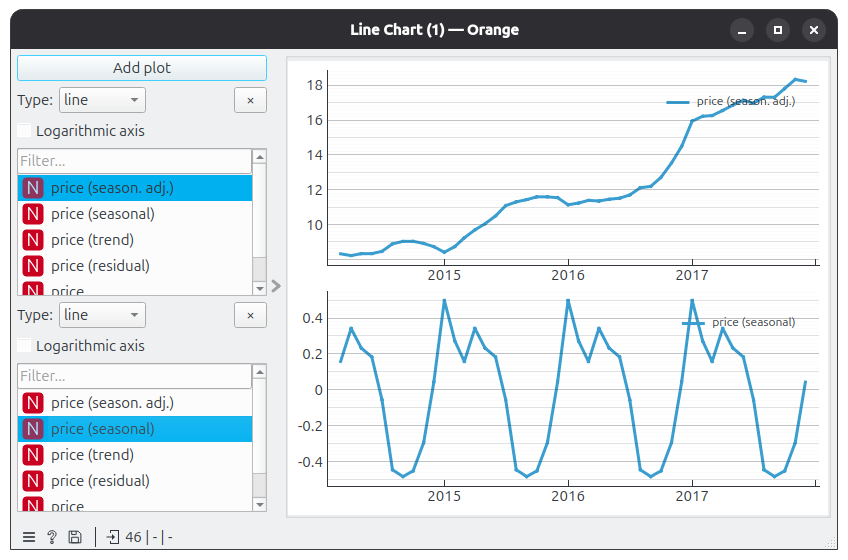

1. **Корелограми на вигляд не збігаються з ACF із завдання 5, хоча числа ті самі.** Orange для вихідного ряду показав лише один стовпчик - лаг 33 (-0,44), а для різниці - лаги 8 (-0,30), 19 (0,16), 27 (-0,14) і 38 (0,03). Причина у вихідному коді `functions.py`: Orange рахує ту саму `statsmodels.acf`, але потім лишає тільки лаги, де |ACF| - **локальний максимум** серед 3 сусідів з кожного боку (`argrelextrema(..., order=3)`). Я перевірила: значення на цих лагах збігаються з ACF у Python до третього знака. Через це фільтр **ховає саме ті лаги, з яких я робила висновки в завданні 5**: у вихідного ряду ACF спадає монотонно (0,94; 0,87; 0,80 ...), тому локальних піків немає взагалі, а в різниці лаг 1 (0,51) - єдиний значущий - відкидається, бо поруч стоїть лаг 0 = 1. Ще одна відмінність - смуга значущості: Orange рахує її з показаних стовпчиків (±0,34 і ±0,33), а не з усіх лагів. **Висновок той самий, якщо читати числа, а не картинку:** вихідний ряд нестаціонарний (повільно спадна ACF), у першій різниці значущий лише лаг 1, d = 1. За самою корелограмою Orange цього встановити не можна - тут потрібна повна ACF із завдання 5.
2. **Seasonal Adjustment.** Сезонна складова Orange - один і той самий профіль щороку: найнижча у серпні - жовтні (близько -0,45...-0,48 грн, мінімум у вересні), найвища в січні (+0,50) і квітні (+0,34). STL із завдання 4 має ту саму форму: середні по місяцях - мінімум у вересні (-0,69), максимум у січні (+0,56), тобто ціна росте від вересня до січня, а влітку стоїть. Різниця в розмірі: розмах Orange близько 1 грн, а в STL він росте з року в рік (0,6 -> 3,1 грн), бо Seasonal Adjustment - це класичне розкладання `statsmodels.seasonal_decompose` (ковзні середні, сталий сезонний профіль), а STL дозволяє сезонності змінюватися. Сезонно скоригований ряд (верхній графік) майже такий самий, як вихідний: стрибок 2016/17 лишається, бо це не сезонність, а зміна рівня (завдання 8). Модель additive обрано для порівняння з адитивним STL; за завданням 4 правильніша мультиплікативна, і в ній сезонність ще слабша.
3. **Помилка в додатку Timeseries.** Спершу Seasonal Adjustment видав `variable date is not in domain` за будь-яких налаштувань:

   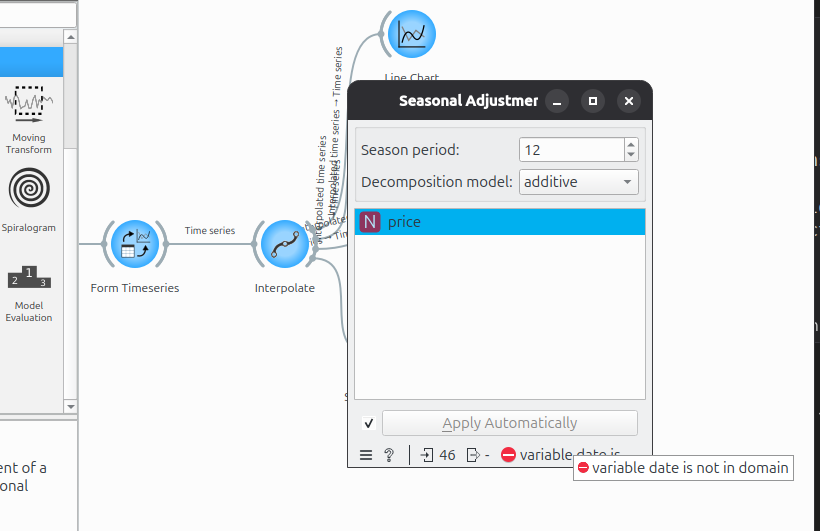

   Причина в коді віджета (`owseasonaladjustment.py`, orange3-timeseries 0.6.3 - остання версія): віджет вирізає з таблиці лише стовпець `price`, але нова таблиця успадковує позначку "часова змінна = date", хоча `date` у ній уже немає, і пошук цього стовпця падає. Я виправила це одним рядком `selected_subset.time_variable = None` після вирізання (дати не губляться: результат приклеюється до вихідної таблиці з `date`). Після цього віджет спрацював, графік вище - уже з виправленим віджетом.

## Завдання 13. Модель і оцінювання

Додайте `ARIMA Model` з порядком **(1, 1, 1)** та `Model Evaluation`.

У віджеті **Model Evaluation** встановіть **Number of folds = 7** та **Forecast steps = 3**.

**У звіті наведіть:**
1. знімок таблиці Model Evaluation з усіма метриками;
2. **що станеться, якщо лишити типові налаштування** (20 фолдів × 3 кроки) — наведіть повідомлення, яке видасть Orange, і поясніть, звідки воно береться;
3. які саме 7 фолдів перевіряє Orange — тобто на яких відрізках ряду навчається модель.

> 💡 **Підказка.** Orange відмовиться працювати при типових налаштуваннях. Це не збій, а наслідок довжини вашого ряду — порахуйте, якої саме.

In [15]:
# Завдання 13. Модель і оцінювання
# Перевірка Orange: n_folds * forecast_steps + max_lag <= len(data)
max_lag = 1   # для ARIMA(1,1,1): max(p, q) = 1
for folds, steps in [(20, 3), (7, 3)]:
    need = folds * steps + max_lag
    print(f'{folds} фолдів x {steps} кроки: потрібно {need} точок, маємо {n} -> '
          f'{"OK" if need <= n else "Orange відмовить"}')
print('максимум фолдів по 3 кроки для нашого ряду:', (n - max_lag) // 3)

20 фолдів x 3 кроки: потрібно 61 точок, маємо 46 -> Orange відмовить
7 фолдів x 3 кроки: потрібно 22 точок, маємо 46 -> OK
максимум фолдів по 3 кроки для нашого ряду: 15


**Висновок до завдання 13:**

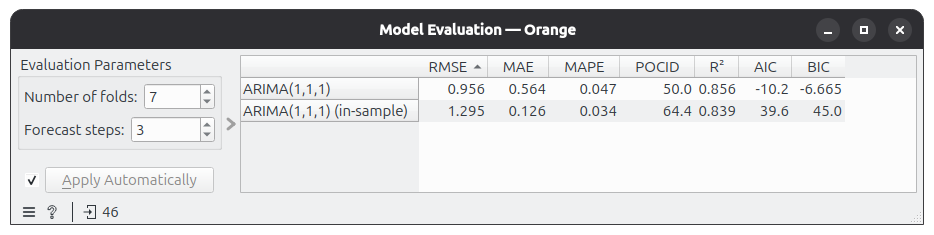

1. Таблиця Model Evaluation - на знімку: для ARIMA(1,1,1) **RMSE 0,956, MAE 0,564, MAPE 0,047, POCID 50,0** (рядок "in-sample" - похибки на навчальних даних, його не порівнюю). Числа перенесено в таблицю завдання 14.
2. **Типові налаштування (20 фолдів × 3 кроки).** Orange видає повідомлення *"Unexpected error: Supplied time series is too short for this many folds / step size. Retry with fewer iterations."*

   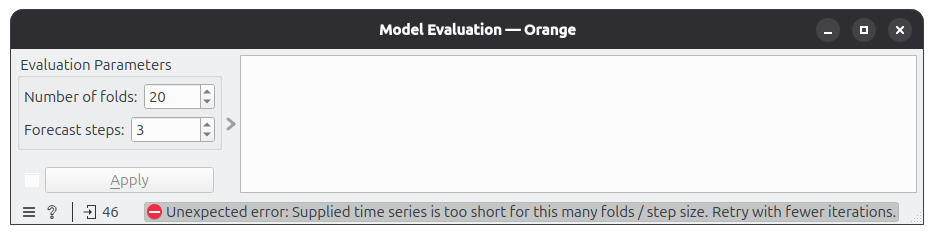

   Воно з перевірки у `functions.py`: `n_folds * forecast_steps + max_lag > len(data)`. Для мого ряду 20 · 3 + 1 = **61 > 46**: щоб зробити 20 прогнозів по 3 місяці, треба перевірити останні 60 місяців, а ряд має лише 46. Найбільше можливо 15 фолдів по 3 кроки, а задано 7 (7 · 3 + 1 = 22 ≤ 46).
3. **Які фолди перевіряє Orange.** Фолд f навчається на всіх точках до позиції -3f і прогнозує наступні 3, f = 1 ... 7, тобто фолди йдуть від кінця ряду назад:

| фолд Orange | навчання | перевірка |
|---|---|---|
| 1 | 03.2014 - 09.2017 (43 міс.) | 10-12.2017 |
| 2 | 03.2014 - 06.2017 (40 міс.) | 07-09.2017 |
| 3 | 03.2014 - 03.2017 (37 міс.) | 04-06.2017 |
| 4 | 03.2014 - 12.2016 (34 міс.) | 01-03.2017 |
| 5 | 03.2014 - 09.2016 (31 міс.) | 10-12.2016 |
| 6 | 03.2014 - 06.2016 (28 міс.) | 07-09.2016 |
| 7 | 03.2014 - 03.2016 (25 міс.) | 04-06.2016 |
   Це ті самі 7 фолдів, що в моїй Частині 1 (я лише перебирала їх у хронологічному порядку), разом - останні 21 місяць.

## Завдання 14. Чому числа не збігаються

Порівняйте метрики Orange з метриками, які ви отримали в Частині 1 для **тієї самої** моделі
ARIMA(1,1,1) на **тих самих** 7 фолдах.

Для кожної з чотирьох метрик Orange — `RMSE`, `MAE`, `MAPE`, `POCID` — **відтворіть її значення в Python**,
тобто напишіть формулу, за якою Orange отримав саме це число, і переконайтеся, що ваш розрахунок
збігається з таблицею Orange до третього знака.

**У звіті наведіть:**
1. таблицю на чотири рядки: метрика · значення Orange · ваше відтворення в Python · формула;
2. **яка з метрик не відповідає своїй назві** — і чим саме вона відрізняється від того, що зазвичай позначають цією абревіатурою;
3. яка метрика збіглася між середовищами одразу і чому;
4. висновок: що саме треба перевіряти, перш ніж порівнювати числа з двох різних інструментів.

> 💡 **Підказка.** Жодна з розбіжностей не є помилкою Orange. Усі формули відкриті — шукайте їх у вихідному коді додатка Timeseries, файл `functions.py`.

In [16]:
# Завдання 14. Чому числа не збігаються
# Формули з orange3-timeseries, functions.py. Orange склеює факт і прогноз усіх фолдів
# в один список (фолд 1 - останні 3 місяці, далі назад у часі) і рахує метрику один раз.
order_orange = np.arange(N_FOLDS)[::-1]   # у true_ar рядки йдуть f = 7, ..., 1; Orange бере f = 1, ..., 7
true_o = true_ar.reshape(N_FOLDS, H)[order_orange].ravel()   # порядок фолдів як в Orange
pred_o = pred_ar.reshape(N_FOLDS, H)[order_orange].ravel()
e = true_o - pred_o

orange_py = {
    'RMSE':  np.sqrt(np.sum(e ** 2) / len(e)),
    'MAE':   np.median(np.abs(e)),
    'MAPE':  np.mean(np.abs(e)) / np.abs(true_o).mean(),
    'POCID': 100 * np.mean((np.diff(true_o) * np.diff(pred_o)) > 0),
}
classic = {'RMSE': m_arima['RMSE'], 'MAE': m_arima['MAE'], 'MAPE': m_arima['MAPE'], 'POCID': np.nan}

# значення з таблиці Model Evaluation в Orange (рядок ARIMA(1,1,1), не in-sample), 3 знаки як в Orange
ORANGE_TABLE = {'RMSE': 0.956, 'MAE': 0.564, 'MAPE': 0.047, 'POCID': 50.0}

t14 = pd.DataFrame({
    'Orange (з таблиці)': ORANGE_TABLE,
    'відтворення в Python': orange_py,
    'класичне означення (Частина 1)': classic,
    'формула Orange': {
        'RMSE':  'sqrt(sum(e^2) / n)',
        'MAE':   'median |e|',
        'MAPE':  'mean|e| / mean|y|  (частка, не %)',
        'POCID': '100 * mean(diff(y) * diff(y_hat) > 0)',
    }})
display(t14.round(4))

if not np.isnan(list(ORANGE_TABLE.values())).all():
    diff = {k: abs(ORANGE_TABLE[k] - orange_py[k]) for k in ORANGE_TABLE}
    print('розбіжність Orange - Python:', {k: round(d, 4) for k, d in diff.items()})
    print('збіг до третього знака:', all(d < 5e-4 for d in diff.values()))

,Orange (з таблиці),відтворення в Python,класичне означення (Частина 1),формула Orange
RMSE,0.956,0.9557,0.9557,sqrt(sum(e^2) / n)
MAE,0.564,0.5642,0.7064,median |e|
MAPE,0.047,0.0471,4.4960,"mean|e| / mean|y| (частка, не %)"
POCID,50.000,50.0000,NaN,100 * mean(diff(y) * diff(y_hat) > 0)


розбіжність Orange - Python: {'RMSE': np.float64(0.0003), 'MAE': np.float64(0.0002), 'MAPE': np.float64(0.0001), 'POCID': np.float64(0.0)}
збіг до третього знака: True


**Висновок до завдання 14:**

1. Таблиця з чотирма метриками наведена вище (стовпець "Orange" - з таблиці Model Evaluation, стовпець "відтворення в Python" - мій розрахунок за формулами з `functions.py` на прогнозах ARIMA(1,1,1) з тих самих 7 фолдів). Значення Orange вписано в `ORANGE_TABLE`; усі чотири збігаються з відтворенням до третього знака (Orange показує 3 знаки, тому різниця < 0,0005).

| метрика | Orange | Python (відтворення) | формула Orange |
|---|---|---|---|
| RMSE | 0,956 | 0,9557 | √(Σe² / n) |
| MAE | 0,564 | 0,5642 | median \|e\| |
| MAPE | 0,047 | 0,0471 | mean\|e\| / mean\|y\| |
| POCID | 50,0 | 50,0 | 100 · частка пар, де знаки diff(y) і diff(ŷ) збігаються |
2. **Не відповідають своїм назвам MAE і MAPE.** "MAE" в Orange - це **медіана** абсолютних похибок (0,564), а не середнє (0,706 у Частині 1): у моєму ряді кілька великих похибок на фолдах стрибка, тому медіана на 20 % менша за середнє. "MAPE" в Orange - це відношення середньої абсолютної похибки до середнього факту, і результат - **частка** (0,0471), а не відсоток; у класичній MAPE кожну похибку ділять на свій факт і множать на 100 (4,50 %). Навіть після множення на 100 числа різні (4,71 % проти 4,50 %), бо середнє відношень не дорівнює відношенню середніх.
3. **Одразу збігся RMSE** (0,956 в обох): формула однакова, і обидва середовища рахують її на одних і тих самих 21 похибках, склеєних з усіх фолдів (Orange теж не усереднює метрики по фолдах, а рахує один раз на всьому списку). Прогнози теж однакові, бо віджет ARIMA - обгортка над тим самим `statsmodels`.
4. **Що перевіряти перед порівнянням чисел з двох інструментів:** (а) ті самі дані на вході (той самий файл, той самий спосіб заповнення пропуску); (б) та сама схема перевірки (кількість фолдів, горизонт, вікно); (в) та сама модель і параметри; (г) **означення кожної метрики** - не назву, а формулу: середнє чи медіана, відсоток чи частка, як агрегуються фолди. Однакова абревіатура не гарантує однакової величини.

## Завдання 15. Матриця напрямку зміни

Метрика `POCID` у Orange вимірює, чи правильно модель передбачає **напрямок** зміни ціни.
Розгорніть її в таблицю 2×2: рядки — що сталося насправді (зросла / впала),
стовпці — що передбачила модель.

**У звіті наведіть:**
1. заповнену матрицю 2×2 для вашої моделі;
2. перевірку, що частка правильних передбачень збігається зі значенням POCID із Orange;
3. висновок: чи корисна ваша модель для рішення «купувати зараз чи чекати», і чому це **інше питання**, ніж те, на яке відповідають MAE та RMSE.

> 💡 **Підказка.** Ця матриця — часоворядовий відповідник матриці похибок із класифікації.

In [17]:
# Завдання 15. Матриця напрямку зміни
# Пари сусідніх точок беремо рівно так, як Orange: np.diff по склеєному списку фолдів
dt, dp = np.diff(true_o), np.diff(pred_o)
real = np.where(dt > 0, 'зросла', 'впала / без змін')
predicted = np.where(dp > 0, 'зросла', 'впала / без змін')
conf = pd.crosstab(pd.Series(real, name='насправді'), pd.Series(predicted, name='передбачено'))
display(conf)

hit = np.mean(dt * dp > 0) * 100
print(f'пар: {len(dt)}, правильний напрямок: {np.sum(dt * dp > 0)} -> {hit:.2f}%  (= POCID)')

# з них пари, що перетинають межу фолдів (сусіди в списку, але не в часі)
cross = np.array([(i + 1) % H == 0 for i in range(len(dt))])
print(f'з {len(dt)} пар {cross.sum()} перетинають межу фолдів;'
      f' лише всередині фолдів: {np.mean((dt * dp > 0)[~cross]) * 100:.2f}%')

# частка, яку дав би найпростіший прогноз "завжди зростає"
print(f'частка місяців зростання серед перевірених пар: {np.mean(dt > 0) * 100:.1f}%')

передбачено,впала / без змін,зросла
насправді,,
впала / без змін,4,5
зросла,5,6


пар: 20, правильний напрямок: 10 -> 50.00%  (= POCID)
з 20 пар 6 перетинають межу фолдів; лише всередині фолдів: 42.86%
частка місяців зростання серед перевірених пар: 55.0%


**Висновок до завдання 15:**

1. Матриця напрямку (пари сусідніх точок рівно так, як їх бере Orange):

| насправді \ передбачено | впала / без змін | зросла |
|---|---|---|
| **впала / без змін** | 4 | 5 |
| **зросла** | 5 | 6 |
2. Правильно вгадано 4 + 6 = **10 з 20 пар = 50 %**, що збігається з POCID (POCID у таблиці Orange = 50,0). Нюанс: Orange рахує `np.diff` по склеєному списку всіх фолдів, тому 6 з 20 пар - це не сусідні місяці, а межі між фолдами (до того ж фолди йдуть від кінця ряду, тож такі "зміни" спрямовані назад у часі). Якщо брати лише пари всередині фолдів, частка ще нижча - 42,9 %.
3. **Для рішення "купувати зараз чи чекати" модель некорисна:** 50 % - це рівень підкидання монети, а наївне правило "ціна завжди зростає" дало б 55 % (ціна зростала в 11 з 20 пар). Це інше питання, ніж MAE і RMSE: вони міряють, **наскільки** прогноз далекий від факту в гривнях, і тут модель непогана (помилка близько 0,7 грн, 4-5 %). Але рішення купівлі залежить лише від **знака** зміни на наступний місяць, а він для молока часто визначається копійками (ціна 2016 року майже не рухалась), де модель з похибкою 0,7 грн вгадувати не може. Як і в класифікації, мала похибка регресії не гарантує правильного класу.

---
# Загальний висновок

Напишіть 8–12 речень, які відповідають на такі питання:

1. Чи є у вашому ряді сезонність і чим ви це довели?
2. Який метод прогнозування виявився найкращим і чи перевершив він найпростіший базис?
3. Чи знайшли ви точку зміни режиму; якщо так — чи є для неї зовнішнє пояснення?
4. Чому однаково названі метрики у двох середовищах дали різні числа?
5. Чого ви не змогли встановити через те, що ряд має лише 46 спостережень?

**Відповідь.**

Роздрібна ціна молока в Черкаській області за 03.2014 - 12.2017 зросла з 8,47 до 18,27 грн за літр (у 2,16 раза), хоча в євро вона за той самий час впала на 21 %, тобто номінальне зростання здебільшого відображає девальвацію гривні; єдиний пропуск (08.2017) - це прогалина збору даних по всьому набору, тому я заповнила його лінійною інтерполяцією. Сезонність у ряді є, але слабка: ціна росте в жовтні - січні й стоїть улітку; адитивний STL дає F_S = 0,76, але розмах коливань росте разом із рівнем, тому правильніша мультиплікативна модель, і на логарифмі F_S = 0,35 - трохи вище порогу 0,3; адитивна оцінка завищена через ріст рівня і тому, що STL частково прийняв стрибок 2016/17 за сезонний ефект. Ряд має дуже сильний тренд (F_T = 0,99) і нестаціонарний, а його перша різниця стаціонарна - ADF і KPSS тут узгоджуються, отже d = 1. Серед базисів найкращий дрейф (MAE 0,737 грн на 7 фолдах по 3 кроки), а ARIMA(1,1,1) обіграла його лише на 4 % (MAE 0,706) і не на всіх фолдах, тому реальної переваги над простим базисом вона не має; за ACF/PACF і AIC я б обрала ще простішу ARIMA(1,1,0). Випадковий поділ 75/25 занижує помилку приблизно вдвічі, тому для часових рядів він непридатний. Точка зміни режиму - січень 2017: середній рівень зріс з 10,45 до 17,08 грн і після цього не повернувся; можливе пояснення - подвоєння мінімальної зарплати з 01.01.2017 і подорожчання сирого молока, але з самих даних це не доводиться. У Orange та сама модель на тих самих фолдах дала однаковий RMSE (0,956), а MAE і MAPE відрізняються, бо Orange під цими назвами рахує медіану абсолютної похибки і відношення середньої похибки до середнього факту (частку, не відсоток) - я відтворила всі чотири числа Orange у Python за формулами з `functions.py`. POCID = 50 % показує, що напрямок зміни ціни модель вгадує не краще за монету. Через те що ряд має лише 46 точок, я не змогла надійно відокремити сезонність від зміни режиму (лише 3,8 сезонних цикли, по 3-4 значення на кожен місяць), оцінити, чи сталий сезонний профіль після 2017 року, і перевірити модель на достатній кількості фолдів - різниця 4 % між ARIMA і дрейфом на 21 точці статистично нічого не означає.

---
# Критерії оцінювання

| Бали | Умова |
|---|---|
| **0** | Ряд не розкладено або прогноз не побудовано. Робота не зарахована. |
| **2** | Виконано лише Частину 1: ряд розкладено й прогноз побудовано, але в Orange аналіз не відтворено. |
| **3** | Виконано обидві частини, проте прогноз не зіставлено з наївним базисом, а розбіжність результатів двох середовищ не пояснено. |
| **4** | Ряд розкладено на складові; прогноз зіставлено з наївним базисом за ретроспективною перевіркою з рухомим початком; той самий аналіз відтворено в Orange; зіставлено результати двох середовищ і пояснено розбіжність метрик. |

**Знімаються бали за:**

* графіки без пояснення вибору геометрії та шкали;
* числа без письмового висновку;
* прогноз без порівняння з базисом;
* висновок «метрики різні, бо середовища різні» без відтворення формул;
* зошит, який не виконується від початку до кінця.

---
# Декларація про використання штучного інтелекту

Використання інструментів штучного інтелекту під час виконання цієї роботи **дозволено**.
Умова одна: ви маєте розуміти кожен рядок зданого коду й кожне написане твердження
і бути готовим пояснити їх на захисті.

Заповніть таблицю. Якщо ШІ не використовувався, напишіть «не використовувався» в першому рядку
й залиште решту порожньою.

| Питання | Ваша відповідь |
|---|---|
| Які інструменти використано (назва, версія) | Claude (Anthropic), модель Opus 5.5, через Claude Code |
| Для яких саме завдань | Частина 1: код і перші варіанти висновків до завдань 1-10, 14, 15. Частина 2: пояснення, як зібрати потік в Orange, і пошук причини помилки в Seasonal Adjustment |
| Що саме було згенеровано (код / текст / пояснення / виправлення помилок) | код Частини 1, чернетки висновків, пояснення формул метрик з `functions.py` |
| Що ви змінили у згенерованому результаті й чому | Попросила перевірити всі графіки й висновки за лекційним зошитом - після цього сезонність перерахували на логарифмі (F_S = 0,35 замість 0,76), додали ціну в євро і змінили кольори графіка 2. Висновки до завдань 11-13 переписані під мої знімки з Orange, бо Orange показав не те, що очікував ШІ |
| Що з отриманого ви **перевірили самостійно** і яким способом | Потік в Orange збирала сама. Звірила Line Chart з графіком із завдання 3, сезонну складову - зі STL, а метрики Model Evaluation (0,956 / 0,564 / 0,047 / 50,0) - з відтворенням у Python, збіглися до третього знака. Сама отримала помилку для 20 фолдів і помилку `variable date is not in domain` у Seasonal Adjustment |
| Чи траплялися у відповідях ШІ помилки; якщо так — які | Так: писав, що ARIMA краща у 4 з 7 фолдів (насправді у 3); спершу оцінив сезонність як сильну, не врахувавши, що коливання ростуть разом із ціною; очікував, що корелограма Orange покаже всі лаги; неправильно назвав типову модель у Seasonal Adjustment |

**Підтверджую, що розумію весь зданий код і всі зроблені висновки
та можу пояснити будь-яку їх частину на захисті роботи.**

Підпис: Козак Наталія  Дата: 30.10.2026